# 02 · xQTL peak dissection and outdoor concordance

Genetic-architecture Manhattans, genome-wide triple-concordance windows (any 3 of the 4 panels), gene / SNP / CADD dissection of every **triple region** (scan footprint of the triple windows, see section 5), and outdoor E&R vs xQTL rank concordance.

**Significance rule everywhere:** a window (or scan position) is a hit when it is at or above its own panel's genome-wide 95th percentile (`Q_CUT`). No flat z cutoffs.

**Outdoor default:** primary track `pooled` (`AF ~ treat.fix + tpt`), window stat `median`, 50 kb. Robustness: Spearman for every track at 50 / 100 / 500 kb × mean / median / max.

### Inputs → outputs

| In | Out (`Final_Final_Data/`) |
|---|---|
| `Data/01_GLM/conc_50kb.csv`, `conc_100kb.csv`, `conc_500kb.csv` | `Data/02_Peaks/scan_logFDR_cutoffs.csv` |
| `Data/01_GLM/rudflies_2023_SvE_GLM_SNP.tsv` | `Data/02_Peaks/window_cutoffs.csv`, `window_peaks_per_panel.csv` |
| `Final_Data_Inputs/xQTL/*/…pseudoscan.chr*.txt` (4 panels, 1 kb scan) | `Data/02_Peaks/triple_overlap_windows.csv`, `triple_peaks.csv`, `triple_regions.csv` |
| `Final_Data_Inputs/xQTL/VCF/{Spino3,Spino4,Spino3Out}_DSPR/calls.chr*.vcf` | `Data/02_Peaks/panel_spearman_jaccard.csv`, `jaccard_threshold_sweep.csv` |
| `Final_Data_Inputs/xQTL/VCF/Spino3_DGRP/all.csv` | `Data/02_Peaks/dmel_gene_coords.csv` (Ensembl archive cache) |
| `Final_Data_Inputs/FLYCADD/<arm>_merged_chunks.csv` | `Data/02_Peaks/triple_region_genes.csv` (File S1), `triple_window_genes.csv` |
| Ensembl BioMart archive (`ENSEMBL_ARCHIVE`) | `Data/02_Peaks/triple_region_AF_<panel>.csv` (dspr3, dspr4, outspino3, dgrp), `triple_region_snp_af.csv` |
| | `Data/02_Peaks/cadd_triple_region_snps_<arm>.csv`, `cadd_qualifying_snps_<arm>.csv` |
| | `Data/02_Peaks/outdoor_xqtl_spearman.csv`, `outdoor_xqtl_spearman_robustness.csv` |
| | `Figures/02_Peaks/*.png` (listed in each cell) |

## 1. Setup

In [1]:
ROOT    <- "D:/xQTL_2025_Data/Final_Window_Analysis/Analysis_jupyter_notebooks/Final_Notebooks"
IN_DIR  <- file.path(ROOT, "Final_Data_Inputs")
OUT_DIR <- file.path(ROOT, "Final_Final_Data")
D_GLM   <- file.path(OUT_DIR, "Data", "01_GLM")
DATA    <- file.path(OUT_DIR, "Data",    "02_Peaks")
FIGS    <- file.path(OUT_DIR, "Figures", "02_Peaks")
for (d in c(DATA, FIGS)) dir.create(d, recursive = TRUE, showWarnings = FALSE)
setwd(OUT_DIR)

CONC_FILES <- c("50kb"  = file.path(D_GLM, "conc_50kb.csv"),
                "100kb" = file.path(D_GLM, "conc_100kb.csv"),
                "500kb" = file.path(D_GLM, "conc_500kb.csv"))
GLM_SNP    <- file.path(D_GLM, "rudflies_2023_SvE_GLM_SNP.tsv")
SCAN_FILES <- c(OutSpino3 = "xQTL/Spino3Out_DSPR/Spino3Out.pseudoscan.chr%s.txt",
                Spino3    = "xQTL/Spino3_DSPR/Step_1kb_Window_50kb.pseudoscan.chr%s.txt",
                Spino4    = "xQTL/Spino4_DSPR/Spino4.pseudoscan.chr%s.txt",
                DGRP      = "xQTL/Spino3_DGRP/Spino3.pseudoscan.chr%s.txt")
VCF_DSPR4  <- "xQTL/VCF/Spino4_DSPR/calls.chr%s.vcf"
DGRP_AF    <- "xQTL/VCF/Spino3_DGRP/all.csv"
FLYCADD    <- "FLYCADD/%s_merged_chunks.csv"
FLYCADD_COLS <- c(POS = 1, REF = 2, ALT = 3, CADD_Score = 4)   # column positions in the headerless FlyCADD files

## ---- analysis constants ------------------------------------------------
Q_CUT    <- 0.95                       # THE significance rule: each panel's own 95th percentile
qcut     <- function(v) unname(quantile(v, Q_CUT, na.rm = TRUE))
WIN      <- 50000
PRIMARY  <- "pooled"
OUT_STAT <- "median"
STATS    <- c("mean", "median", "max")
NSHIFT   <- 10000                       # circular-shift permutations
GAP_MAX  <- 500000                     # per-panel peak caller: merge hit windows <= this apart
SCAN_HALF  <- 50000                    # X-QTL scan half-width (haplotype.parameters `size`): value at pos summarizes pos +/- 50 kb
POS_OFFSET <- WIN / 2                  # notebook 01 POS_IS = "center": scan position = win_start + 25 kb
CADD_MIN <- 0.6                        # FlyCADD score cutoff for "qualifying" variants
ENSEMBL_ARCHIVE <- "Jun 2026"
CHROMS   <- c("2L", "2R", "3L", "3R", "X")
DSPR_DROP <- c("AB8", paste0("B", 1:7))                       # samples excluded from the DSPR model
set.seed(1)

suppressPackageStartupMessages({
  library(tidyverse); library(data.table); library(patchwork); library(ggtext); library(ggnewscale)
  library(GenomicRanges); library(IRanges); library(biomaRt)
  library(gridExtra); library(grid); library(gtable); library(scales)
})

PANELS <- c(z_dgrp = "LC50-DGRP-I", z_dspr3 = "LC50-DSPR-I", z_dspr4 = "LC90-DSPR-I", z_outspino3 = "LC50-DSPR-O")
PANELS_MD <- c(z_dgrp      = "LC50-<span style='color:#d1495b'>DGRP</span>-I",
               z_dspr3     = "LC50-DSPR-I",
               z_dspr4     = "<span style='color:#d1495b'>LC90</span>-DSPR-I",
               z_outspino3 = "LC50-DSPR-<span style='color:#d1495b'>O</span>")
DSPR_Z    <- c("z_dspr3", "z_dspr4", "z_outspino3")
BASE_COLS <- c(z_dgrp = "#9d4edd", z_dspr3 = "#457b9d", z_dspr4 = "#2a9d8f", z_outspino3 = "#e76f51")

## ---- helpers -----------------------------------------------------------
strip_chr <- function(x) sub("^chr", "", x)

## rotate v within each chromosome by a random offset: keeps each track's spatial
## autocorrelation (LD blocks), breaks alignment between tracks. v sorted by chr, pos.
circ_shift <- function(v, chr) {
  out <- v
  for (ix in split(seq_along(v), chr)) {
    n <- length(ix); if (n < 2) next
    k <- sample.int(n - 1L, 1L)
    out[ix] <- v[ix][c((k + 1):n, 1:k)]
  }
  out
}

TPT_DATE <- c(tpt1 = "Aug 24", tpt2 = "Sep 30", tpt3 = "Oct 27", tpt4 = "Nov 24")
out_lab  <- function(tg) ifelse(tg == PRIMARY, "Across all timepoints", unname(TPT_DATE[tg]))

## cumulative genome layout from a table with chr / win_end
chr_layout <- function(df, pad = 1e6) {
  df %>% group_by(chr) %>% summarise(chr_len = max(win_end), .groups = "drop") %>%
    mutate(ord = match(chr, CHROMS)) %>% arrange(ord) %>%
    mutate(offset = cumsum(lag(chr_len + pad, default = 0)), center = offset + chr_len / 2) %>%
    dplyr::select(-ord)
}

## styled table -> PNG (+ inline draw)
save_table_png <- function(disp, title, file, foot = NULL, italic_col = NULL, fontsize = 7) {
  th <- ttheme_minimal(
    core    = list(fg_params = list(hjust = 0, x = 0.05, fontsize = fontsize),
                   bg_params = list(fill = c("white", "grey95"), col = NA)),
    colhead = list(fg_params = list(fontface = "bold", hjust = 0, x = 0.05, fontsize = fontsize + 1, col = "white"),
                   bg_params = list(fill = SUP_BLUE, col = NA)))
  tg <- tableGrob(disp, rows = NULL, theme = th)
  if (!is.null(italic_col)) {
    sel <- tg$layout$name == "core-fg" & tg$layout$l == which(colnames(disp) == italic_col)
    tg$grobs[sel] <- lapply(tg$grobs[sel], function(gr) { gr$gp$font <- 3L; gr })
  }
  tit <- textGrob(title, gp = gpar(fontface = "bold", fontsize = 9))
  tab <- gtable_add_rows(tg, heights = grobHeight(tit) + unit(6, "mm"), pos = 0)
  tab <- gtable_add_grob(tab, tit, t = 1, l = 1, r = ncol(tg), clip = "off")
  if (!is.null(foot)) {
    ft  <- textGrob(foot, x = 0.01, hjust = 0, gp = gpar(fontsize = 6, col = "grey40", fontface = "italic"))
    tab <- gtable_add_rows(tab, heights = grobHeight(ft) + unit(4, "mm"), pos = -1)
    tab <- gtable_add_grob(tab, ft, t = nrow(tab), l = 1, r = ncol(tab), clip = "off")
  }
  pdf(NULL)
  gw <- max(convertWidth(sum(tab$widths), "in", valueOnly = TRUE),
            convertWidth(grobWidth(tit), "in", valueOnly = TRUE))
  gh <- convertHeight(sum(tab$heights), "in", valueOnly = TRUE)
  dev.off()
  png(file, width = gw + 0.8, height = gh + 0.8, units = "in", res = 300, bg = "white")
  grid.newpage(); pushViewport(viewport(width = unit(gw, "in"), height = unit(gh, "in")))
  grid.draw(tab); popViewport(); dev.off()
  grid.newpage(); grid.draw(tab)
  invisible(tab)
}

## ---- window tables -----------------------------------------------------
conc   <- lapply(CONC_FILES, function(f) as.data.frame(fread(f)) %>% mutate(chr = as.character(chr)))
conc50 <- conc[["50kb"]]
OUT_TAGS <- unique(sub("^out_(.+)_(mean|median|max)$", "\\1",
                       grep("^out_.+_(mean|median|max)$", names(conc50), value = TRUE)))
OUT_TAGS <- c(PRIMARY, setdiff(sort(OUT_TAGS), PRIMARY))
stopifnot(PRIMARY %in% OUT_TAGS)
cat("outdoor tracks:", paste(OUT_TAGS, collapse = ", "), "| primary:", PRIMARY,
    "| window stat:", OUT_STAT, "\n")
cat("50kb windows:", nrow(conc50), "\n")

## ---- publication style shared by every figure (main + supplement) --------
SUP_RED     <- "#D2232A"; SUP_BLUE <- "#0057B8"
PANEL_ORDER <- c("z_dspr3", "z_dgrp", "z_dspr4", "z_outspino3")      # reference (LC50-DSPR-I) first
PANEL_COL   <- c("LC50-DSPR-I" = "#457b9d", "LC50-DGRP-I" = "#9d4edd", "LC90-DSPR-I" = "#2a9d8f",
                 "LC50-DSPR-O" = "#E9A23B", "Outdoor E&R" = "#6c757d")
W_FULL <- 180 / 25.4; W_HALF <- 85 / 25.4
mm     <- function(x) x / 25.4
theme_pub <- function(base = 8) {
  theme_classic(base_size = base) +
    theme(axis.line = element_line(linewidth = 0.3), axis.ticks = element_line(linewidth = 0.3),
          axis.ticks.length = unit(2, "pt"), axis.text = element_text(size = 7, colour = "black"),
          axis.title = element_text(size = 8),
          strip.background = element_blank(), strip.text = element_text(size = 7, face = "bold", hjust = 0),
          legend.title = element_text(size = 6.5, face = "bold"), legend.text = element_text(size = 6),
          legend.key.size = unit(7, "pt"), legend.margin = margin(0, 0, 0, 0),
          plot.title = element_text(size = 8, face = "bold"),
          plot.subtitle = element_text(size = 6.5, colour = "grey30"),
          plot.margin = margin(4, 6, 4, 4))
}
TAG_THEME <- theme(plot.tag = element_text(size = 10, face = "bold"))
save_pub <- function(p, name, w = W_FULL, h, dpi = 600) {
  ggsave(file.path(FIGS, paste0(name, ".png")), p, width = w, height = h, dpi = dpi, bg = "white", limitsize = FALSE)
  ggsave(file.path(FIGS, paste0(name, ".pdf")), p, width = w, height = h, device = cairo_pdf, limitsize = FALSE)
  options(repr.plot.width = w * 1.5, repr.plot.height = h * 1.5)
  invisible(p)
}

Warning message:
"package 'tidyverse' was built under R version 4.4.2"
Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Warning message:
"package 'tibble' was built under R version 4.4.1"
Warning message:
"package 'tidyr' was built under R version 4.4.1"
Warning message:
"package 'readr' was built under R version 4.4.2"
Warning message:
"package 'purrr' was built under R version 4.4.3"
Warning message:
"package 'dplyr' was built under R version 4.4.1"
Warning message:
"package 'stringr' was built under R version 4.4.3"
Warning message:
"package 'forcats' was built under R version 4.4.2"
Warning message:
"package 'lubridate' was built under R version 4.4.2"
Warning message:
"package 'data.table' was built under R version 4.4.3"
Warning message:
"package 'patchwork' was built under R version 4.4.3"
Warning message:
"package 'ggtext' was built under R version 4.4.3"
Warning message:
"package 'ggnewscale' was built under R version 4.4.3"
Warning message:
"package 'Genom

outdoor tracks: pooled, tpt1, tpt2, tpt3, tpt4 | primary: pooled | window stat: median 
50kb windows: 1951 


## 2. Scan-level (1 kb step) xQTL Manhattans

These plot the raw scans themselves, so BH here runs over every scan position within a panel (the window-level z used everywhere else is BH over non-overlapping 50 kb windows, built in notebook 01). Cutoff line = each panel's own 95th percentile of −log10(FDR).

Figure: `stacked_scan_manhattans.png`. Data: `scan_logFDR_cutoffs.csv`.

# A tibble: 4 × 3
  panel       cut   rate
  <chr>     <dbl>  <dbl>
1 DGRP       8.90 0.0500
2 OutSpino3  3.00 0.0500
3 Spino3     4.87 0.0500
4 Spino4     8.21 0.0500


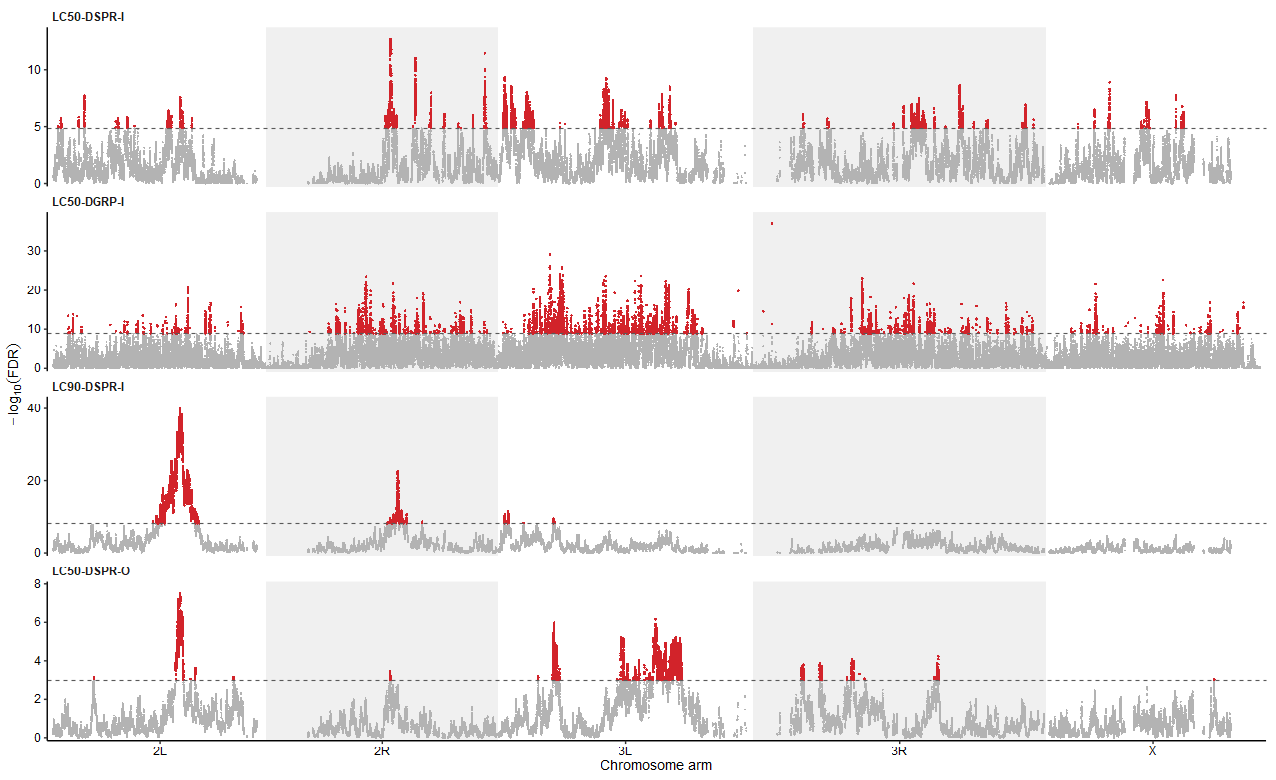

In [2]:
SCAN_LAB   <- c(OutSpino3 = "LC50-DSPR-O", Spino3 = "LC50-DSPR-I", Spino4 = "LC90-DSPR-I", DGRP = "LC50-DGRP-I")
SCAN_ORDER <- c("Spino3", "DGRP", "Spino4", "OutSpino3")          # same order as Figure 2

## read.table (not fread): the scan files carry row names, which read.table detects
scan <- bind_rows(lapply(names(SCAN_FILES), function(pn) {
  bind_rows(lapply(CHROMS, function(ch) read.table(file.path(IN_DIR, sprintf(SCAN_FILES[[pn]], ch))))) %>%
    filter(is.finite(Wald_log10p)) %>%
    transmute(panel = pn, chr = strip_chr(as.character(chr)), pos = as.numeric(pos),
              raw_p = 10^(-pmin(Wald_log10p, 300))) %>%
    mutate(FDR_p = p.adjust(raw_p, method = "BH"), logFDR = -log10(FDR_p))
}))

LOGFDR_CUT <- scan %>% group_by(panel) %>% summarise(cut = qcut(logFDR), rate = mean(logFDR >= qcut(logFDR)))
print(LOGFDR_CUT)            # BH q has ties, so >= cut can pass slightly more than 5%
write.csv(LOGFDR_CUT, file.path(DATA, "scan_logFDR_cutoffs.csv"), row.names = FALSE)
LOGFDR_CUT <- setNames(LOGFDR_CUT$cut, LOGFDR_CUT$panel)

scan_off <- scan %>% group_by(chr) %>% summarise(chr_len = max(pos), .groups = "drop") %>%
  mutate(ord = match(chr, CHROMS)) %>% arrange(ord) %>% mutate(offset = lag(cumsum(chr_len), default = 0))
scan <- scan %>% left_join(dplyr::select(scan_off, chr, offset), by = "chr") %>%
  mutate(cum_pos = pos + offset, sig = logFDR >= LOGFDR_CUT[panel])
scan_axis <- scan %>% group_by(chr) %>% summarise(center = mean(range(cum_pos)), .groups = "drop")
scan_band <- scan_off %>% mutate(xmin = offset, xmax = offset + chr_len) %>% filter(row_number() %% 2 == 0)

## ---- Supplement: scan-level Manhattans, one panel per experiment -----------
scan_lab_f <- function(p) factor(SCAN_LAB[p], levels = SCAN_LAB[SCAN_ORDER])
scan_plot  <- scan %>% mutate(panel_lab = scan_lab_f(panel))
cut_scan   <- tibble(panel = names(LOGFDR_CUT), cut = unname(LOGFDR_CUT)) %>% mutate(panel_lab = scan_lab_f(panel))
stacked <- ggplot(scan_plot, aes(cum_pos, logFDR)) +
  geom_rect(data = scan_band, aes(xmin = xmin, xmax = xmax), ymin = -Inf, ymax = Inf,
            fill = "grey94", inherit.aes = FALSE) +
  geom_point(data = ~ filter(.x, !sig), colour = "grey70", size = 0.3, stroke = 0) +
  geom_point(data = ~ filter(.x,  sig), colour = SUP_RED, size = 0.45, stroke = 0) +
  geom_hline(data = cut_scan, aes(yintercept = cut), linetype = "dashed", linewidth = 0.25, colour = "grey35") +
  facet_wrap(~ panel_lab, ncol = 1, scales = "free_y") +
  scale_x_continuous(breaks = scan_axis$center, labels = scan_axis$chr, expand = c(0.005, 0)) +
  scale_y_continuous(breaks = scales::breaks_pretty(3), expand = expansion(mult = c(0.02, 0.08))) +
  labs(x = "Chromosome arm", y = expression(-log[10](FDR))) +
  theme_pub() + theme(panel.spacing.y = unit(3, "pt"))
save_pub(stacked, "stacked_scan_manhattans", h = mm(110), dpi = 400)
stacked

## 3. Window-level cutoffs (50 kb)

Per-panel 95th percentile of the window |z| (from BH-adjusted window p), plus the same cutoff in SD units of each panel's genome-wide distribution (standardizing is monotone, so the same windows pass). Data: `window_cutoffs.csv`.

In [3]:
window_cutoffs <- conc50 %>%
  dplyr::select(all_of(names(PANELS))) %>%
  pivot_longer(everything(), names_to = "zcol", values_to = "z") %>%
  filter(!is.na(z)) %>%
  group_by(zcol) %>%
  summarise(n_windows = n(), z_cut = qcut(z), n_hit = sum(z > z_cut), pct_hit = mean(z > z_cut),
            z_cut_sd = (z_cut - mean(z)) / sd(z), .groups = "drop") %>%
  mutate(panel = PANELS[zcol], implied_q = 2 * pnorm(-z_cut)) %>%
  relocate(panel)
print(window_cutoffs, n = Inf)
write.csv(window_cutoffs, file.path(DATA, "window_cutoffs.csv"), row.names = FALSE)
Z_CUT <- setNames(window_cutoffs$z_cut, window_cutoffs$zcol)[names(PANELS)]

# A tibble: 4 × 8
  panel       zcol        n_windows z_cut n_hit pct_hit z_cut_sd implied_q
  <chr>       <chr>           <int> <dbl> <int>   <dbl>    <dbl>     <dbl>
1 LC50-DGRP-I z_dgrp           1951  6.37    98  0.0502     1.84  1.88e-10
2 LC50-DSPR-I z_dspr3          1951  4.36    98  0.0502     1.72  1.29e- 5
3 LC90-DSPR-I z_dspr4          1951  5.92    98  0.0502     1.81  3.14e- 9
4 LC50-DSPR-O z_outspino3      1951  3.35    96  0.0492     1.97  8.13e- 4


## 4. Window z Manhattans with per-panel peaks

Hit windows (≥ own 95th percentile) merged into peaks when ≤ `GAP_MAX` apart. Figure: `window_z_peak_manhattans.png`. Data: `window_peaks_per_panel.csv`.

# A tibble: 4 × 2
  panel       n_peaks
  <chr>         <int>
1 LC50-DGRP-I      36
2 LC50-DSPR-I      26
3 LC50-DSPR-O      12
4 LC90-DSPR-I       4


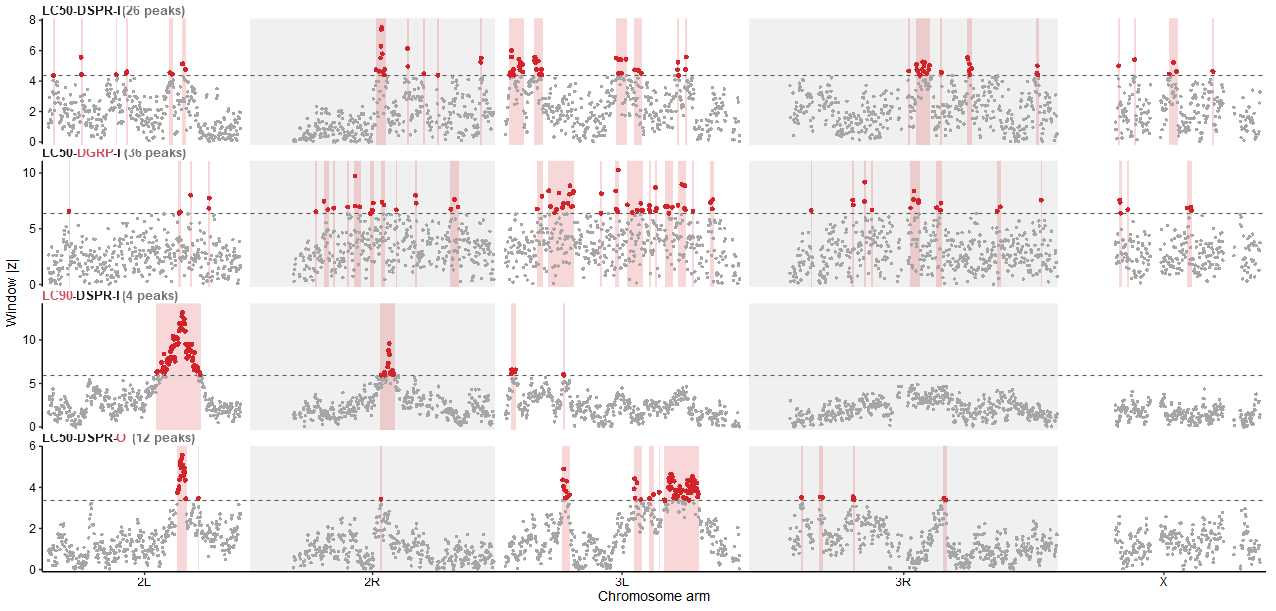

In [4]:
call_peaks <- function(df, zcol, z_thresh = Z_CUT[[zcol]], gap_max = GAP_MAX) {
  d <- df %>% transmute(chr, win_start, win_end, z = .data[[zcol]]) %>%
    filter(z > z_thresh) %>% arrange(chr, win_start)
  if (nrow(d) == 0) return(tibble())
  d %>% group_by(chr) %>%
    mutate(new_peak = is.na(lag(win_start)) | (win_start - lag(win_start)) > gap_max) %>%
    ungroup() %>% mutate(peak_id = cumsum(new_peak)) %>%
    group_by(peak_id, chr) %>%
    summarise(start = min(win_start), end = max(win_end), n_win = n(),
              z_max = max(z), z_mean = mean(z), .groups = "drop") %>%
    mutate(zcol = !!zcol, panel = !!unname(PANELS[[zcol]]), len_bp = end - start) %>%
    relocate(panel, zcol) %>% arrange(chr, start)
}
peaks_all <- bind_rows(lapply(names(PANELS), call_peaks, df = conc50))
print(count(peaks_all, panel, name = "n_peaks"))
write.csv(peaks_all, file.path(DATA, "window_peaks_per_panel.csv"), row.names = FALSE)

## ---- Figure 2: per-panel window Manhattans (publication) ------------------
FIG_W <- 180 / 25.4                 # double-column width (mm -> in); use 85 mm for single column
FIG_H <- 115 / 25.4 * 0.75
PANEL_ORDER <- c("z_dspr3", "z_dgrp", "z_dspr4", "z_outspino3")   # reference (LC50-DSPR-I) first

chr_info <- chr_layout(conc50)
band     <- chr_info %>% mutate(xmin = offset, xmax = offset + chr_len) %>% filter(row_number() %% 2 == 0)

n_pk <- count(peaks_all, zcol, name = "n_peaks")
strip_lab <- setNames(sprintf("%s  <span style='color:grey45'>(%d peaks)</span>", PANELS_MD[PANEL_ORDER],
                              replace_na(n_pk$n_peaks[match(PANEL_ORDER, n_pk$zcol)], 0L)),
                      PANEL_ORDER)
as_panel <- function(z) factor(z, levels = PANEL_ORDER, labels = strip_lab[PANEL_ORDER])

df_long <- conc50 %>% dplyr::select(chr, win_start, all_of(PANEL_ORDER)) %>%
  pivot_longer(all_of(PANEL_ORDER), names_to = "zcol", values_to = "z") %>%
  left_join(dplyr::select(chr_info, chr, offset), by = "chr") %>%
  mutate(cum_pos = win_start + offset, sig = z > Z_CUT[zcol], panel = as_panel(zcol))
peaks_cum <- peaks_all %>% left_join(dplyr::select(chr_info, chr, offset), by = "chr") %>%
  mutate(cum_start = start + offset, cum_end = end + offset, panel = as_panel(zcol))
cut_df <- tibble(zcol = PANEL_ORDER, z_cut = unname(Z_CUT[PANEL_ORDER])) %>%
  mutate(panel = as_panel(zcol))

g_peaks <- ggplot(df_long, aes(cum_pos, z)) +
  geom_rect(data = band, inherit.aes = FALSE, aes(xmin = xmin, xmax = xmax, ymin = -Inf, ymax = Inf),
            fill = "grey94") +
  geom_rect(data = peaks_cum, inherit.aes = FALSE, aes(xmin = cum_start, xmax = cum_end, ymin = -Inf, ymax = Inf),
            fill = "#D2232A", alpha = 0.18) +
  geom_hline(data = cut_df, aes(yintercept = z_cut), linetype = "dashed", linewidth = 0.25, colour = "grey35") +
  geom_point(data = filter(df_long, !sig), colour = "grey65", size = 0.7, stroke = 0) +
  geom_point(data = filter(df_long,  sig), colour = "#D2232A", size = 1.1, stroke = 0) +
  facet_wrap(~ panel, ncol = 1, scales = "free_y") +
  scale_x_continuous(breaks = chr_info$center, labels = chr_info$chr, expand = c(0.005, 0)) +
  scale_y_continuous(breaks = scales::breaks_pretty(3), expand = expansion(mult = c(0.02, 0.08))) +
  labs(x = "Chromosome arm", y = "Window |z|") +
  theme_classic(base_size = 8) +
  theme(strip.background  = element_blank(),
        strip.text        = element_markdown(face = "bold", size = 7.5, hjust = 0, margin = margin(b = 1)),
        panel.spacing.y   = unit(3, "pt"),
        axis.line         = element_line(linewidth = 0.3),
        axis.ticks        = element_line(linewidth = 0.3),
        axis.ticks.length = unit(2, "pt"),
        axis.text         = element_text(size = 7, colour = "black"),
        axis.title        = element_text(size = 8),
        plot.margin       = margin(4, 6, 4, 4))

ggsave(file.path(FIGS, "window_z_peak_manhattans.png"), g_peaks, width = FIG_W, height = FIG_H, dpi = 600, bg = "white")
ggsave(file.path(FIGS, "window_z_peak_manhattans.pdf"), g_peaks, width = FIG_W, height = FIG_H, device = cairo_pdf)
options(repr.plot.width = FIG_W * 1.5, repr.plot.height = FIG_H * 1.5)
g_peaks

## 5. Triple-concordance windows (genome-wide, any 3 of 4 panels)

Every 50 kb window at or above its own 95th percentile in **at least three** of the four xQTL panels (LC50-DGRP-I, LC50-DSPR-I, LC90-DSPR-I, LC50-DSPR-O), in any combination; a window hit in all four is included. `hit_set` / `hit_code` record which panels; `z_min`, `win_max_z` and `top_panel` are computed over the hit panels only. `top_panel` (the window's / peak's **strongest experiment**) is the hit panel with the highest |z| relative to its own 95th-percentile cutoff (`z / Z_CUT`), because raw |z| is not comparable across experiments (cutoffs range 3.35-6.37). Every SNP-level inference downstream (section 11, CADD) uses each peak's strongest experiment. Contiguous triple windows are merged into peaks.

**Triple regions (the unit for every gene, SNP, CADD and transcriptomic analysis).** Each X-QTL value at a scan position summarizes ±`SCAN_HALF` (50 kb) of sequence, so 50 kb window edges are finer than the data resolve and gene lists built on them move when the sampling grid shifts. A region is therefore the scan footprint of its triple windows: first scan position − 50 kb to last scan position + 50 kb. Peaks whose footprints lie ≤ `GAP_MAX` apart are merged with the gaps between them (this is the 2L Consensus region). Window-level results (counts, Jaccard, Figures 3 and 4) still use the 50 kb windows.

Data: `triple_overlap_windows.csv`, `triple_peaks.csv`, `triple_regions.csv`.

In [5]:
MIN_HITS <- 3                                        # triple = >= 3 of the 4 panels, any combination
zall  <- names(PANELS)
SHORT <- c(z_dgrp = "DGRP", z_dspr3 = "I50", z_dspr4 = "I90", z_outspino3 = "O50")

hitM <- sapply(zall, function(cc) conc50[[cc]] > Z_CUT[[cc]])
keep <- rowSums(hitM) >= MIN_HITS
H    <- hitM[keep, , drop = FALSE]
ZH   <- as.matrix(conc50[keep, zall]); ZH[!H] <- NA      # z of hit panels only
ZR   <- sweep(ZH, 2, Z_CUT[zall], "/")                    # strength relative to each panel's own cutoff

triple_windows <- conc50[keep, ] %>%
  mutate(n_hits    = rowSums(H),
         hit_set   = apply(H, 1, function(r) paste(PANELS[zall][r], collapse = " & ")),
         hit_code  = apply(H, 1, function(r) paste(SHORT[zall][r], collapse = "+")),
         dgrp_hit  = H[, "z_dgrp"],
         z_min     = apply(ZH, 1, min, na.rm = TRUE),
         win_max_z   = apply(ZH, 1, max, na.rm = TRUE),
         win_max_rel = apply(ZR, 1, max, na.rm = TRUE),
         top_panel   = unname(PANELS[zall][max.col(replace(ZR, is.na(ZR), -Inf), ties.method = "first")]),
         window_id = sprintf("%s:%d", chr, as.integer(win_start))) %>%
  arrange(match(chr, CHROMS), win_start) %>%
  group_by(chr) %>%
  mutate(peak = sprintf("%s_%d", chr, cumsum(is.na(lag(win_end)) | win_start != lag(win_end)))) %>%
  ungroup() %>%
  dplyr::select(window_id, peak, chr, win_start, win_end, n_hits, hit_set, hit_code, dgrp_hit,
                all_of(DSPR_Z), z_dgrp, z_min, win_max_z, win_max_rel, top_panel)
stopifnot(nrow(triple_windows) > 0)

triple_peaks <- triple_windows %>%
  group_by(peak, chr) %>%
  summarise(start = min(win_start), end = max(win_end), n_win = n(),
            span_kb = (max(win_end) - min(win_start)) / 1000,
            max_z = max(win_max_z), max_z_pos = win_start[which.max(win_max_z)],
            top_panel = top_panel[which.max(win_max_rel)], max_rel = max(win_max_rel),
            hit_sets = paste(unique(hit_code), collapse = "; "), max_hits = max(n_hits),
            any_dgrp = any(dgrp_hit), .groups = "drop") %>%
  arrange(match(chr, CHROMS), start)

write.csv(triple_windows, file.path(DATA, "triple_overlap_windows.csv"), row.names = FALSE)
write.csv(triple_peaks,   file.path(DATA, "triple_peaks.csv"),          row.names = FALSE)
cat(sprintf("triple windows (>= %d of 4 panels): %d in %d peaks on %s\n", MIN_HITS,
            nrow(triple_windows), nrow(triple_peaks), paste(unique(triple_windows$chr), collapse = ", ")))
print(count(triple_windows, hit_set, name = "n_windows"))
print(triple_windows %>% dplyr::select(window_id, peak, hit_code, all_of(zall), z_min, top_panel), n = Inf, width = Inf)
print(triple_peaks, n = Inf, width = Inf)

## ---- triple regions: scan footprint of the triple peaks, merged within GAP_MAX ----------
## first scan position - SCAN_HALF to last scan position + SCAN_HALF; gaps between merged peaks included
triple_regions <- triple_peaks %>%
  mutate(fp_start = start + POS_OFFSET - SCAN_HALF,           # start = first win_start = first pos - 25 kb
         fp_end   = end   - POS_OFFSET + SCAN_HALF) %>%       # end   = last win_end   = last pos + 25 kb
  arrange(match(chr, CHROMS), fp_start) %>%
  group_by(chr) %>%
  mutate(region_n = cumsum(is.na(lag(fp_end)) | (fp_start - lag(fp_end)) > GAP_MAX)) %>%
  group_by(chr, region_n) %>%
  summarise(n_peaks = n(), peaks = paste(peak, collapse = ","),
            fp_start = min(fp_start), fp_end = max(fp_end), n_win = sum(n_win),
            top_panel = top_panel[which.max(max_rel)], max_rel = max(max_rel), max_z = max(max_z),
            hit_sets = paste(unique(unlist(strsplit(hit_sets, "; "))), collapse = "; "),
            .groups = "drop") %>%
  mutate(region  = make.unique(ifelse(n_peaks > 1, paste0(chr, "_Consensus"), peaks)),
         span_kb = (fp_end - fp_start) / 1000) %>%
  dplyr::select(region, chr, fp_start, fp_end, span_kb, n_peaks, peaks, n_win, hit_sets, top_panel, max_rel, max_z) %>%
  arrange(match(chr, CHROMS), fp_start)
peak2region <- triple_regions %>% separate_rows(peaks, sep = ",") %>% dplyr::select(peak = peaks, region)
triple_peaks   <- triple_peaks   %>% left_join(peak2region, by = "peak")
triple_windows <- triple_windows %>% left_join(peak2region, by = "peak")
write.csv(triple_windows, file.path(DATA, "triple_overlap_windows.csv"), row.names = FALSE)
write.csv(triple_peaks,   file.path(DATA, "triple_peaks.csv"),          row.names = FALSE)
write.csv(triple_regions, file.path(DATA, "triple_regions.csv"),        row.names = FALSE)
cat("\ntriple regions (scan footprint, peaks <= GAP_MAX apart merged):\n")
print(triple_regions %>% dplyr::select(region, chr, fp_start, fp_end, span_kb, peaks, hit_sets, top_panel), n = Inf, width = Inf)


for (q in c(0.90, 0.925, 0.95, 0.975, 0.99)) {
  cuts <- sapply(zall, function(cc) unname(quantile(conc50[[cc]], q, na.rm = TRUE)))
  h <- rowSums(sapply(zall, function(cc) conc50[[cc]] > cuts[[cc]])) >= MIN_HITS
  w <- conc50[h, ]
  cat(sprintf("top %2.0f%%: %2d triple windows | 2L 13.5-14.4 Mb: %d | arms: %s\n",
              100 * (1 - q), nrow(w),
              sum(w$chr == "2L" & w$win_start >= 13.5e6 & w$win_start < 14.4e6),
              paste(sort(unique(w$chr)), collapse = ", ")))
}

triple windows (>= 3 of 4 panels): 8 in 7 peaks on 2L, 2R, 3L
# A tibble: 3 × 2
  hit_set                                 n_windows
  <chr>                                       <int>
1 LC50-DGRP-I & LC50-DSPR-I & LC50-DSPR-O         1
2 LC50-DGRP-I & LC90-DSPR-I & LC50-DSPR-O         3
3 LC50-DSPR-I & LC90-DSPR-I & LC50-DSPR-O         4
# A tibble: 8 × 9
  window_id   peak  hit_code     z_dgrp z_dspr3 z_dspr4 z_outspino3 z_min
  <chr>       <chr> <chr>         <dbl>   <dbl>   <dbl>       <dbl> <dbl>
1 2L:13585000 2L_1  DGRP+I90+O50   6.38    2.46   11.0         4.03  4.03
2 2L:13735000 2L_2  DGRP+I90+O50   6.51    3.62   11.3         5.26  5.26
3 2L:13935000 2L_3  I50+I90+O50    3.37    5.13   13.1         5.58  5.13
4 2L:13985000 2L_3  I50+I90+O50    2.47    5.14   11.9         5.08  5.08
5 2L:14235000 2L_4  I50+I90+O50    2.86    4.76   11.0         4.35  4.35
6 2R:13491000 2R_1  I50+I90+O50    5.16    6.29    5.95        3.42  3.42
7 3L:6202000  3L_1  DGRP+I90+O50   7.26    2.54   

## 6. Mirrored scan Manhattan: LC50-DGRP-I (top) vs DSPR treatments (bottom)

Gold = scan positions above their own cutoff that fall inside a triple window **in which that panel is one of the hits**, so "triple" means the same thing here as everywhere else (a DSPR scan point inside a DGRP + 2-DSPR window is gold only if its panel is one of the two DSPR hits). Figure: `mirrored_scan_manhattan.png`.

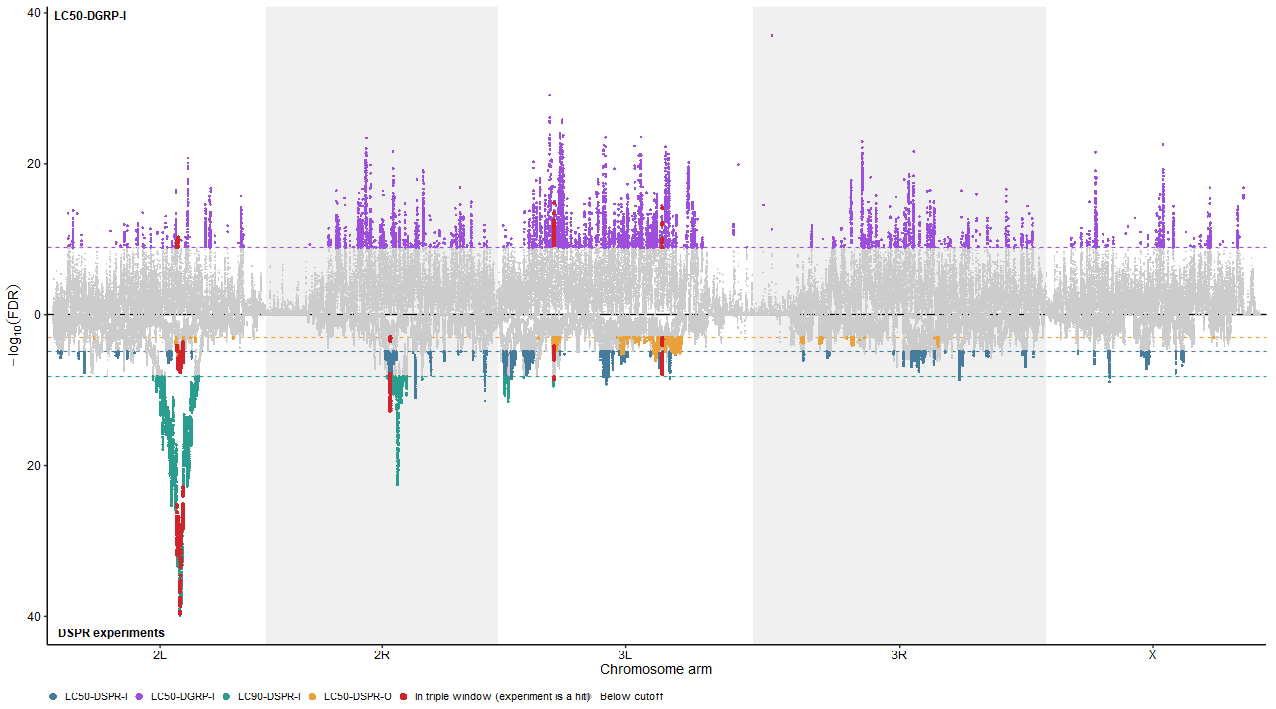

In [6]:
SCAN_Z  <- c(OutSpino3 = "z_outspino3", Spino3 = "z_dspr3", Spino4 = "z_dspr4", DGRP = "z_dgrp")
scan_dt <- as.data.table(scan)[, zcol := unname(SCAN_Z[panel])]
tri_hit <- melt(as.data.table(triple_windows)[, c("chr", "win_start", "win_end", zall), with = FALSE],
                id.vars = c("chr", "win_start", "win_end"), variable.name = "zcol", value.name = "z")
tri_hit[, zcol := as.character(zcol)]
tri_hit <- tri_hit[z > Z_CUT[zcol]]                    # (window, panel) pairs where the panel is a hit
scan_dt[, in_triple := FALSE]
scan_dt[tri_hit, on = .(zcol, chr, pos >= win_start, pos < win_end), in_triple := TRUE]

## ---- Supplement: mirrored scan Manhattan, DGRP up / DSPR down --------------
TRI_LAB <- "In triple window (experiment is a hit)"
mir_lev <- c(SCAN_LAB[SCAN_ORDER], TRI_LAB, "Below cutoff")
mir_pal <- c(setNames(unname(PANEL_COL[SCAN_LAB[SCAN_ORDER]]), SCAN_LAB[SCAN_ORDER]),
             setNames(SUP_RED, TRI_LAB), "Below cutoff" = "grey80")
mir_siz <- c(setNames(rep(0.5, 4), SCAN_LAB[SCAN_ORDER]), setNames(0.9, TRI_LAB), "Below cutoff" = 0.25)
combined_scan <- as_tibble(scan_dt) %>%
  mutate(y   = ifelse(panel == "DGRP", logFDR, -logFDR),
         cls = case_when(sig & in_triple ~ TRI_LAB, sig ~ unname(SCAN_LAB[panel]), TRUE ~ "Below cutoff"),
         cls = factor(cls, levels = mir_lev),
         ord = match(as.character(cls), c("Below cutoff", SCAN_LAB[SCAN_ORDER], TRI_LAB))) %>%
  arrange(ord)
cut_y   <- c(LOGFDR_CUT[["DGRP"]], -LOGFDR_CUT[c("Spino3", "Spino4", "OutSpino3")])
cut_col <- unname(PANEL_COL[c("LC50-DGRP-I", "LC50-DSPR-I", "LC90-DSPR-I", "LC50-DSPR-O")])

scan_mirror <- ggplot(combined_scan, aes(cum_pos, y, colour = cls, size = cls)) +
  geom_rect(data = scan_band, aes(xmin = xmin, xmax = xmax), ymin = -Inf, ymax = Inf,
            fill = "grey94", inherit.aes = FALSE) +
  geom_hline(yintercept = unname(cut_y), colour = cut_col, linetype = "dashed", linewidth = 0.25) +
  geom_hline(yintercept = 0, colour = "black", linewidth = 0.3) +
  geom_point(stroke = 0) +
  annotate("text", x = -Inf, y = Inf,  label = "LC50-DGRP-I", hjust = -0.1, vjust = 1.5,  size = 2.4, fontface = "bold") +
  annotate("text", x = -Inf, y = -Inf, label = "DSPR experiments", hjust = -0.1, vjust = -0.8, size = 2.4, fontface = "bold") +
  scale_colour_manual(values = mir_pal, name = NULL, drop = FALSE) +
  scale_size_manual(values = mir_siz, guide = "none") +
  scale_x_continuous(breaks = scan_axis$center, labels = scan_axis$chr, expand = c(0.005, 0)) +
  scale_y_continuous(labels = abs, name = expression(-log[10](FDR))) +
  labs(x = "Chromosome arm") +
  guides(colour = guide_legend(nrow = 1, override.aes = list(size = 1.8))) +
  theme_pub() + theme(legend.position = "bottom", legend.justification = "left")
save_pub(scan_mirror, "mirrored_scan_manhattan", h = mm(100), dpi = 400)
scan_mirror

## 7. Concordance-class window Manhattan (all four panels)

Each hit window is coloured by its exact set of panels above their own 95th percentile: singles, pairs, triples and the four-way class. Figure: `concordance_class_manhattan.png`.

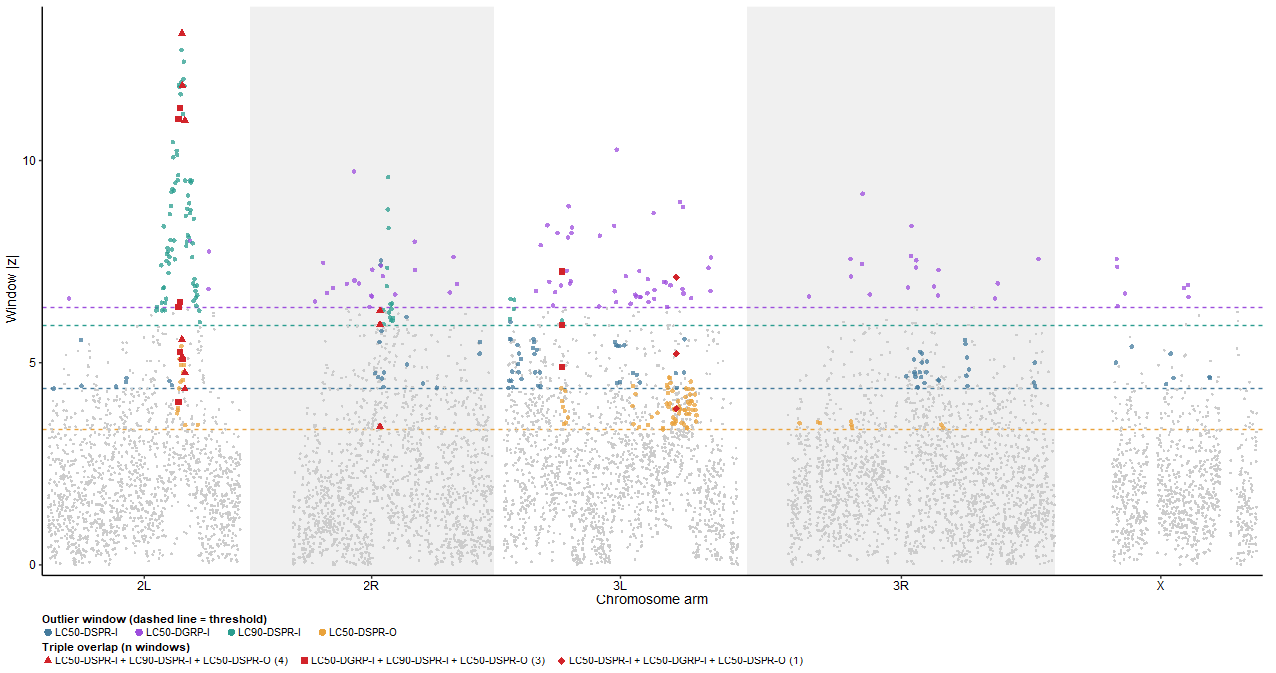

In [7]:
## ---- Figure 3A: concordance-class Manhattan (publication) -----------------
FIG_W3 <- 180 / 25.4
FIG_H3 <- 95 / 25.4                       # room for two titled legend rows
PANEL_ORDER <- c("z_dspr3", "z_dgrp", "z_dspr4", "z_outspino3")   # reference first, same as Fig 2

SUP_RED   <- "#D2232A"                    # triple overlap
panel_col <- c("LC50-DSPR-I" = "#457b9d", "LC50-DGRP-I" = "#9d4edd",
               "LC90-DSPR-I" = "#2a9d8f", "LC50-DSPR-O" = "#E9A23B")

sig_mat <- sapply(zall, function(cc) conc50[[cc]] > Z_CUT[[cc]])
cls <- conc50 %>%
  mutate(tier  = rowSums(sig_mat),
         combo = apply(sig_mat[, PANEL_ORDER, drop = FALSE], 1,
                       function(r) paste(PANELS[PANEL_ORDER][r], collapse = " + ")))
stopifnot(setequal(sprintf("%s:%d", cls$chr, as.integer(cls$win_start))[cls$tier >= MIN_HITS],
                   triple_windows$window_id))

d_cls <- cls %>%
  left_join(dplyr::select(chr_info, chr, offset), by = "chr") %>%
  mutate(cum = win_start + offset) %>%
  pivot_longer(all_of(zall), names_to = "zcol", values_to = "z") %>%
  mutate(hit   = z > Z_CUT[zcol],
         panel = factor(PANELS[zcol], levels = PANELS[PANEL_ORDER]),
         class = case_when(!hit ~ "none", tier >= MIN_HITS ~ "triple", TRUE ~ "other"))

## triple combos present -> one basic shape each (fillable: red fill, black outline)
tri_n   <- cls %>% filter(tier >= MIN_HITS) %>% count(combo) %>% arrange(desc(n))
tri_shp <- setNames(c(24, 22, 23, 21, 25)[seq_len(nrow(tri_n))], tri_n$combo)
tri_lab <- setNames(sprintf("%s (%d)", tri_n$combo, tri_n$n), tri_n$combo)
d_tri   <- d_cls %>% filter(class == "triple") %>% mutate(combo = factor(combo, levels = tri_n$combo))

band_grey <- chr_info %>% mutate(xmin = offset, xmax = offset + chr_len) %>% filter(row_number() %% 2 == 0)

combo_man <- ggplot() +
  geom_rect(data = band_grey, aes(xmin = xmin, xmax = xmax), ymin = -Inf, ymax = Inf,
            fill = "grey94", inherit.aes = FALSE) +
  geom_hline(yintercept = unname(Z_CUT[zall]), colour = unname(panel_col[PANELS[zall]]),
             linetype = "dashed", linewidth = 0.3) +
  geom_point(data = filter(d_cls, class == "none"), aes(cum, z),
             colour = "grey80", size = 0.5, stroke = 0) +
  geom_point(data = filter(d_cls, class == "other"), aes(cum, z, colour = panel),
             size = 1, alpha = 0.75, stroke = 0) +
  geom_point(data = d_tri, aes(cum, z, shape = combo),
             fill = SUP_RED, colour = "black", size = 1.7, stroke = 0) +
  scale_colour_manual(values = panel_col, name = "Outlier window (dashed line = threshold)",
                      guide = guide_legend(order = 1, nrow = 1, override.aes = list(size = 1.8, alpha = 1))) +
  scale_shape_manual(values = tri_shp, labels = tri_lab, name = "Triple overlap (n windows)",
                     guide = guide_legend(order = 2, nrow = 1, override.aes = list(size = 1.8))) +
  scale_x_continuous(breaks = chr_info$center, labels = chr_info$chr, expand = c(0.005, 0)) +
  scale_y_continuous(expand = expansion(mult = c(0.02, 0.05))) +
  labs(x = "Chromosome arm", y = "Window |z|") +
  theme_classic(base_size = 8) +
  theme(axis.line             = element_line(linewidth = 0.3),
        axis.ticks            = element_line(linewidth = 0.3),
        axis.ticks.length     = unit(2, "pt"),
        axis.text             = element_text(size = 7, colour = "black"),
        axis.title            = element_text(size = 8),
        legend.position       = "bottom",
        legend.box            = "vertical",
        legend.box.just       = "left",
        legend.justification  = "left",
        legend.title.position = "top",
        legend.title          = element_text(size = 6, face = "bold", margin = margin(b = 1)),
        legend.text           = element_text(size = 6, margin = margin(l = 1, r = 6)),
        legend.key.size       = unit(7, "pt"),
        legend.spacing.y      = unit(2, "pt"),
        legend.margin         = margin(0, 0, 0, 0),
        legend.box.spacing    = unit(3, "pt"),
        plot.margin           = margin(4, 8, 4, 4))

ggsave(file.path(FIGS, "concordance_class_manhattan.png"), combo_man, width = FIG_W3, height = FIG_H3, dpi = 600, bg = "white")
ggsave(file.path(FIGS, "concordance_class_manhattan.pdf"), combo_man, width = FIG_W3, height = FIG_H3, device = cairo_pdf)
options(repr.plot.width = FIG_W3 * 1.5, repr.plot.height = FIG_H3 * 1.5)
combo_man

### Supplemental Figure for cut-offs

Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's shape values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's shape values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's shape values."


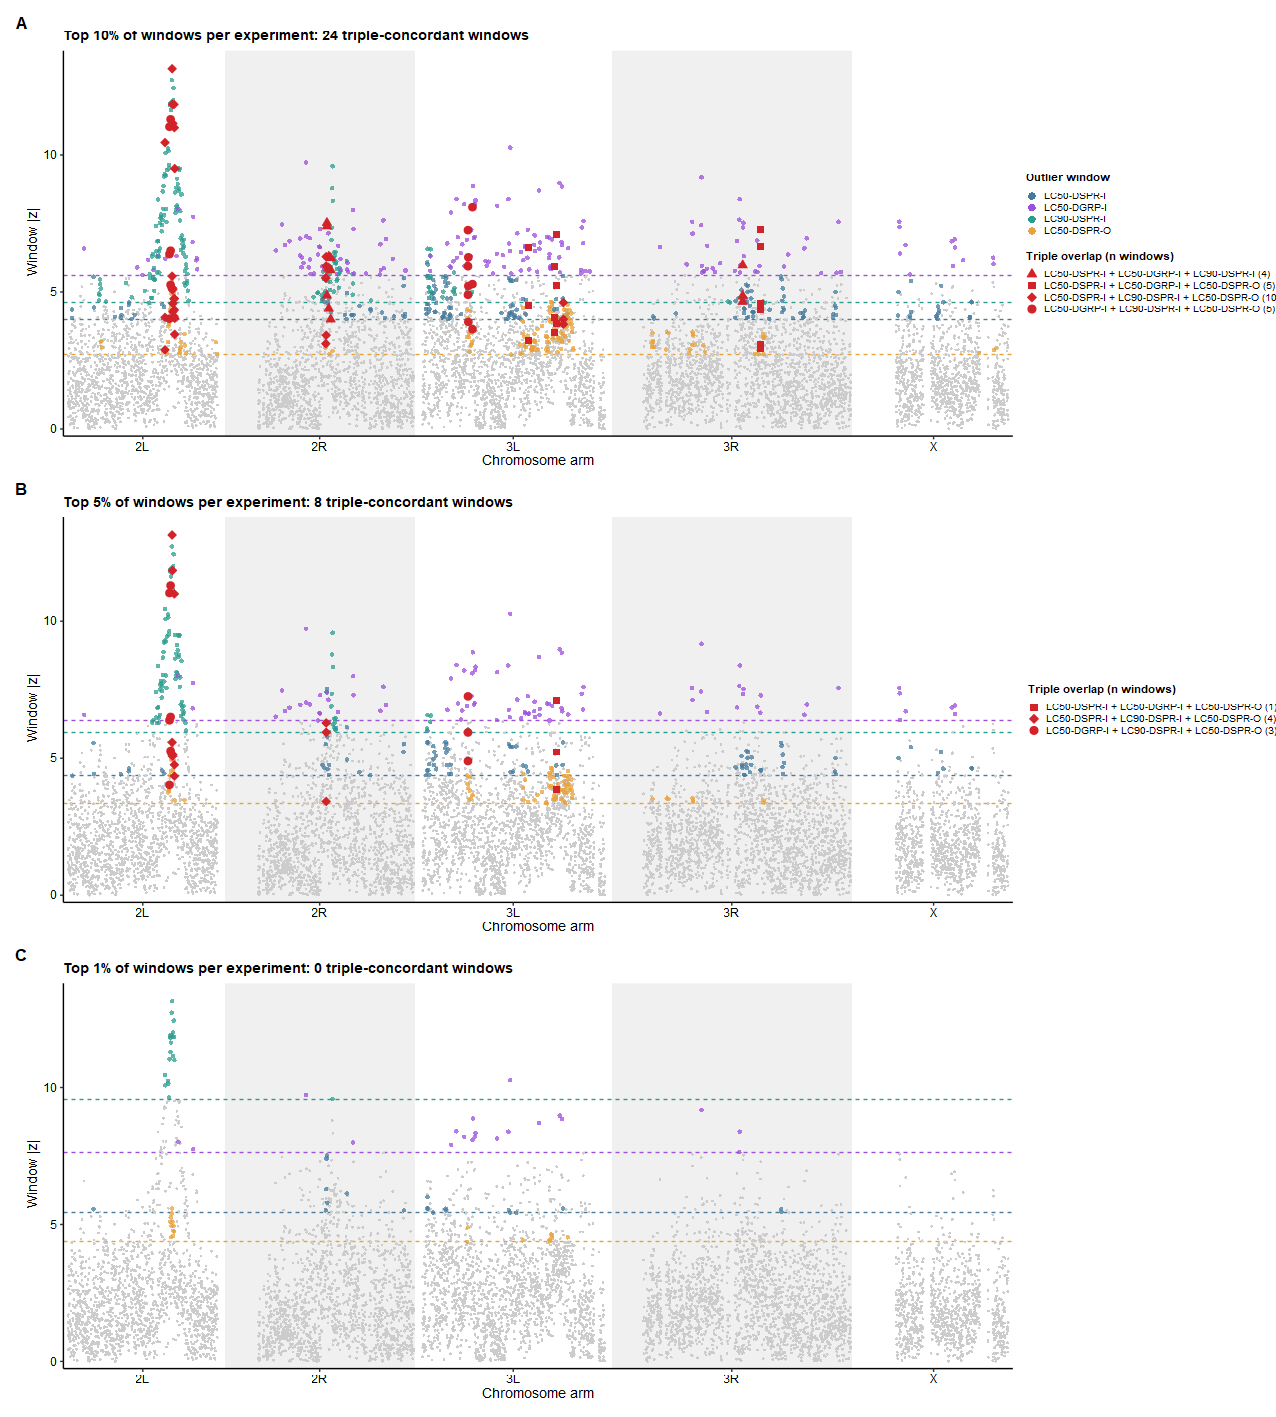

In [8]:
## ---- Supplemental: concordance Manhattan at alternative thresholds ---------
Q_SWEEP <- c(0.90, 0.95, 0.99)
ALL_TRI <- unlist(lapply(3:4, function(k) combn(PANEL_ORDER, k, function(x) paste(PANELS[x], collapse = " + "))))
ALL_SHP <- setNames(c(24, 22, 23, 21, 25), ALL_TRI)          # fixed shape per combo across panels

make_combo_man <- function(q, show_colour_legend = FALSE) {
  cuts <- sapply(zall, function(cc) unname(quantile(conc50[[cc]], q, na.rm = TRUE)))
  sm   <- sapply(zall, function(cc) conc50[[cc]] > cuts[[cc]])
  cl   <- conc50 %>%
    mutate(tier  = rowSums(sm),
           combo = apply(sm[, PANEL_ORDER, drop = FALSE], 1,
                         function(r) paste(PANELS[PANEL_ORDER][r], collapse = " + ")))
  dd <- cl %>%
    left_join(dplyr::select(chr_info, chr, offset), by = "chr") %>%
    mutate(cum = win_start + offset) %>%
    pivot_longer(all_of(zall), names_to = "zcol", values_to = "z") %>%
    mutate(hit   = z > cuts[zcol],
           panel = factor(PANELS[zcol], levels = PANELS[PANEL_ORDER]),
           class = case_when(!hit ~ "none", tier >= MIN_HITS ~ "triple", TRUE ~ "other"))
  tri      <- dd %>% filter(class == "triple") %>% mutate(combo = factor(combo, levels = ALL_TRI))
  tri_cnt  <- table(factor(cl$combo[cl$tier >= MIN_HITS], levels = ALL_TRI))
  present  <- ALL_TRI[tri_cnt > 0]
  n_tri    <- sum(cl$tier >= MIN_HITS)

  ggplot() +
    geom_rect(data = band_grey, aes(xmin = xmin, xmax = xmax), ymin = -Inf, ymax = Inf,
              fill = "grey94", inherit.aes = FALSE) +
    geom_hline(yintercept = unname(cuts[zall]), colour = unname(panel_col[PANELS[zall]]),
               linetype = "dashed", linewidth = 0.3) +
    geom_point(data = filter(dd, class == "none"), aes(cum, z), colour = "grey80", size = 0.5, stroke = 0) +
    geom_point(data = filter(dd, class == "other"), aes(cum, z, colour = panel), size = 1, alpha = 0.75, stroke = 0) +
    geom_point(data = tri, aes(cum, z, shape = combo), fill = SUP_RED, colour = SUP_RED, size = 1.7, stroke = 0.3) +
    scale_colour_manual(values = panel_col, name = "Outlier window",
                        guide = if (show_colour_legend) guide_legend(order = 1, override.aes = list(size = 1.8, alpha = 1)) else "none") +
    scale_shape_manual(values = ALL_SHP, breaks = present, drop = FALSE,
                       labels = sprintf("%s (%d)", present, as.integer(tri_cnt[present])),
                       name = "Triple overlap (n windows)",
                       guide = guide_legend(order = 2, override.aes = list(size = 1.8))) +
    scale_x_continuous(breaks = chr_info$center, labels = chr_info$chr, expand = c(0.005, 0)) +
    scale_y_continuous(expand = expansion(mult = c(0.02, 0.05))) +
    labs(x = "Chromosome arm", y = "Window |z|",
         title = sprintf("Top %d%% of windows per experiment: %d triple-concordant window%s",
                         round(100 * (1 - q)), n_tri, ifelse(n_tri == 1, "", "s"))) +
    theme_pub() +
    theme(legend.position = "right",
          legend.title    = element_text(size = 6, face = "bold"),
          legend.text     = element_text(size = 5.5),
          legend.key.size = unit(7, "pt"))
}

sweep_plots <- lapply(seq_along(Q_SWEEP), function(i) make_combo_man(Q_SWEEP[i], show_colour_legend = i == 1))
fig_sweep <- wrap_plots(sweep_plots, ncol = 1) +
  plot_annotation(tag_levels = "A") & TAG_THEME
save_pub(fig_sweep, "concordance_class_manhattan_threshold_sweep", h = mm(200), dpi = 400)
fig_sweep

## 8. Pairwise panel concordance: Jaccard (95th-pct hits) + Spearman

Spearman p from the circular-shift null (one panel rotated within chromosome), alongside the naive `cor.test` p, which treats windows as independent and is anti-conservative. Data: `panel_spearman_jaccard.csv`. Figures: `panel_jaccard_spearman_heatmap.png`, `manhattan_heatmap_combined.png`.

# A tibble: 6 × 13
  a      b     panel1 panel2 n_windows hits1 hits2  both jaccard    rho  p_naive
  <chr>  <chr> <chr>  <chr>      <int> <dbl> <dbl> <dbl>   <dbl>  <dbl>    <dbl>
1 z_dgrp z_ds… LC50-… LC50-…      1951    98    98     7  0.0370 0.0622 5.99e- 3
2 z_dgrp z_ds… LC50-… LC90-…      1951    98    98     4  0.0208 0.130  8.13e- 9
3 z_dgrp z_ou… LC50-… LC50-…      1951    98    96    13  0.0718 0.108  1.92e- 6
4 z_dsp… z_ds… LC50-… LC90-…      1951    98    98    10  0.0538 0.145  1.27e-10
5 z_dsp… z_ou… LC50-… LC50-…      1951    98    96     9  0.0486 0.106  2.88e- 6
6 z_dsp… z_ou… LC90-… LC50-…      1951    98    96    21  0.121  0.189  3.40e-17
# ℹ 2 more variables: p_circ <dbl>, p_circ_BH <dbl>


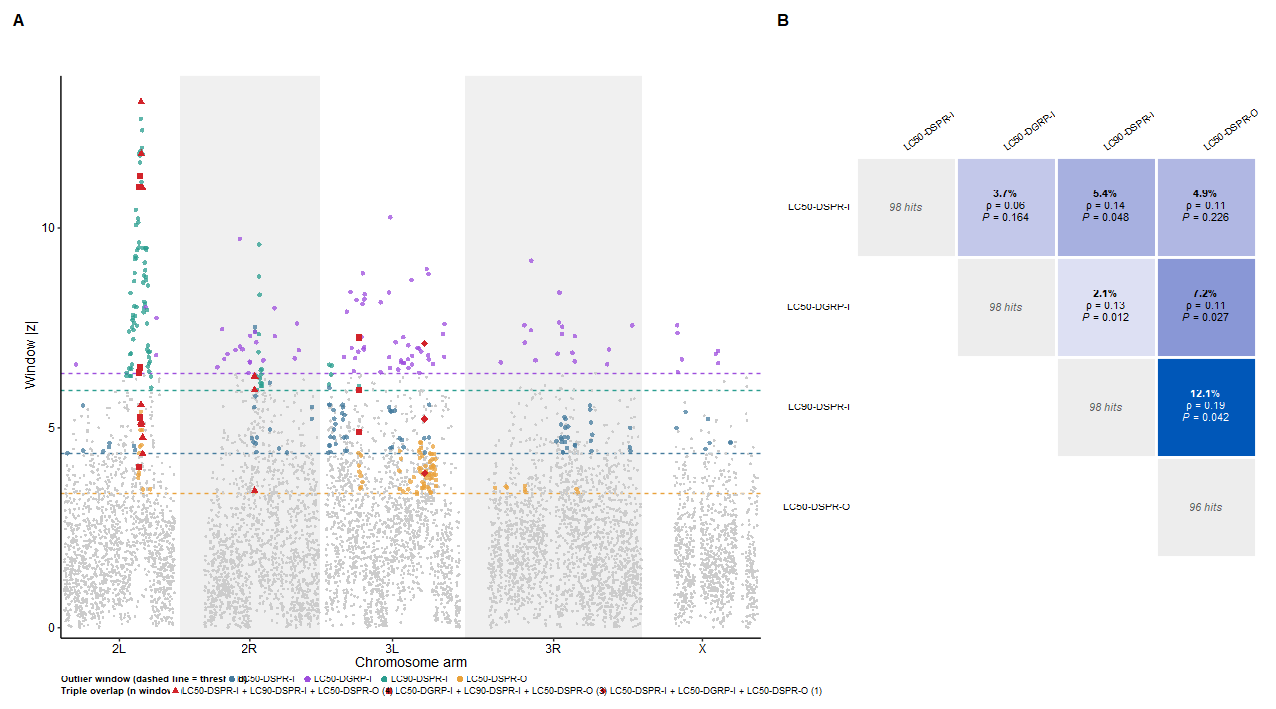

In [9]:
## ---- pairwise Jaccard + Spearman (stats) ------------------------------------
B <- conc50[, zall]; keep_b <- complete.cases(B)
B <- B[keep_b, ]; B_chr <- conc50$chr[keep_b]
n_win  <- nrow(B)
M      <- sweep(as.matrix(B), 2, Z_CUT[zall], ">")
n_hits <- colSums(M)
both   <- crossprod(M)
jacc   <- both / (outer(n_hits, n_hits, "+") - both)
R      <- sapply(B, rank)
rho    <- cor(R)

pairs <- t(combn(zall, 2))
panel_tab <- bind_rows(lapply(seq_len(nrow(pairs)), function(i) {
  a <- pairs[i, 1]; b <- pairs[i, 2]
  r_ab <- rho[a, b]
  null <- replicate(NSHIFT, cor(R[, a], circ_shift(R[, b], B_chr)))
  tibble(a = a, b = b, panel1 = PANELS[[a]], panel2 = PANELS[[b]], n_windows = n_win,
         hits1 = n_hits[[a]], hits2 = n_hits[[b]], both = both[a, b], jaccard = jacc[a, b],
         rho = r_ab,
         p_naive = suppressWarnings(cor.test(B[[a]], B[[b]], method = "spearman")$p.value),
         p_circ  = (1 + sum(abs(null) >= abs(r_ab))) / (NSHIFT + 1))
})) %>% mutate(p_circ_BH = p.adjust(p_circ, "BH"))
print(panel_tab)
write.csv(dplyr::select(panel_tab, -a, -b), file.path(DATA, "panel_spearman_jaccard.csv"), row.names = FALSE)

## ---- Figure 3B: Jaccard / Spearman heatmap ----------------------------------
SUP_BLUE <- "#0057B8"
P_mat <- matrix(NA_real_, length(zall), length(zall), dimnames = list(zall, zall))
P_mat[cbind(panel_tab$a, panel_tab$b)] <- panel_tab$p_circ
P_mat[cbind(panel_tab$b, panel_tab$a)] <- panel_tab$p_circ

lab_order <- unname(PANELS[PANEL_ORDER])
long_h <- expand.grid(a = PANEL_ORDER, b = PANEL_ORDER, stringsAsFactors = FALSE) %>%
  mutate(ia = match(a, PANEL_ORDER), ib = match(b, PANEL_ORDER), is_diag = a == b,
         both = both[cbind(a, b)], jacc = jacc[cbind(a, b)], rho = rho[cbind(a, b)],
         p = P_mat[cbind(a, b)],
         fill_val = ifelse(is_diag, NA_real_, jacc * 100),
         a = factor(PANELS[a], levels = lab_order), b = factor(PANELS[b], levels = rev(lab_order))) %>%
  filter(ia >= ib)
fill_max <- max(long_h$fill_val, na.rm = TRUE)
long_h <- long_h %>%
  mutate(txt_col = ifelse(!is_diag & fill_val > 0.6 * fill_max, "white", "black"),
         lab = ifelse(is_diag, sprintf("%d hits", both),
                      sprintf("**%.1f%%**<br>\u03C1 = %.2f<br>%s", jacc * 100, rho,
                              ifelse(p < 0.001, "*P* < 0.001", sprintf("*P* = %.3f", p)))))

heat_plot <- ggplot(long_h, aes(a, b)) +
  geom_tile(aes(fill = fill_val), colour = "white", linewidth = 0.6) +
  geom_richtext(data = ~ filter(.x, !is_diag), aes(label = lab, colour = txt_col),
                size = 2.3, lineheight = 1.1, fill = NA, label.colour = NA,
                label.padding = unit(0, "pt")) +
  geom_text(data = ~ filter(.x, is_diag), aes(label = lab),
            size = 2.3, colour = "grey35", fontface = "italic") +
  scale_colour_identity() +
  scale_fill_gradient(low = "white", high = SUP_BLUE, limits = c(0, NA), na.value = "grey93", guide = "none") +
  scale_x_discrete(expand = c(0, 0), position = "top") + scale_y_discrete(expand = c(0, 0)) +
  coord_equal(clip = "off") + labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 8) +
  theme(axis.text.x.top = element_text(size = 5.5, colour = "black", angle = 35, hjust = 0, vjust = 0),
        axis.text.y     = element_text(size = 5.5, colour = "black"),
        panel.grid      = element_blank(),
        plot.margin     = margin(10, 14, 4, 4))
ggsave(file.path(FIGS, "panel_jaccard_spearman_heatmap.png"), heat_plot,
       width = 80 / 25.4, height = 75 / 25.4, dpi = 600, bg = "white")

## ---- Figure 3: A (Manhattan) + B (heatmap) ----------------------------------
FIG_W3C <- 180 / 25.4
FIG_H3C <- 100 / 25.4
combo_man_c <- combo_man +
  guides(colour = guide_legend(order = 1, nrow = 1, override.aes = list(size = 1.5, alpha = 1)),
         shape  = guide_legend(order = 2, nrow = 1, override.aes = list(size = 1.5)))
combined_fig <- combo_man_c + heat_plot +
  plot_layout(widths = c(1.75, 1), guides = "collect") +
  plot_annotation(tag_levels = "A") &
  theme(plot.tag              = element_text(size = 10, face = "bold"),
        legend.position       = "bottom",
        legend.location       = "plot",
        legend.box            = "vertical",
        legend.box.just       = "left",
        legend.justification  = c(0, 0.5),
        legend.title.position = "left",
        legend.title          = element_text(size = 5, face = "bold", margin = margin(r = 3)),
        legend.text           = element_text(size = 5, margin = margin(l = 1, r = 4)),
        legend.key.size       = unit(6, "pt"),
        legend.spacing.y      = unit(1, "pt"),
        legend.margin         = margin(0, 0, 0, 0),
        legend.box.margin     = margin(0, 0, 0, 0),
        legend.box.spacing    = unit(2, "pt"),
        plot.margin           = margin(4, 6, 4, 4))
ggsave(file.path(FIGS, "manhattan_heatmap_combined.png"), combined_fig,
       width = FIG_W3C, height = FIG_H3C, dpi = 600, bg = "white")
ggsave(file.path(FIGS, "manhattan_heatmap_combined.pdf"), combined_fig,
       width = FIG_W3C, height = FIG_H3C, device = cairo_pdf)
options(repr.plot.width = FIG_W3C * 1.5, repr.plot.height = FIG_H3C * 1.5)
combined_fig

### Robustness: Jaccard across quantile cutoffs

Every panel cut at its own (1 − frac) quantile for frac = 10 / 5 / 1 %. Robustness check only; the main rule stays 95th. Data: `jaccard_threshold_sweep.csv`. Figure: `jaccard_threshold_table.png`.

# A tibble: 7 × 4
  `Panel pairing`               `top 10%` `top 5%` `top 1%`
  <chr>                         <chr>     <chr>    <chr>   
1 LC50-DGRP-I vs LC50-DSPR-I    6.3%      3.7%     0.0%    
2 LC50-DGRP-I vs LC50-DSPR-O    11.2%     7.2%     0.0%    
3 LC50-DGRP-I vs LC90-DSPR-I    6.6%      2.1%     0.0%    
4 LC50-DSPR-I vs LC50-DSPR-O    9.3%      4.9%     0.0%    
5 LC50-DSPR-I vs LC90-DSPR-I    8.3%      5.4%     0.0%    
6 LC90-DSPR-I vs LC50-DSPR-O    13.8%     12.1%    37.9%   
7 Triple-concordant windows (n) 24        8        0       


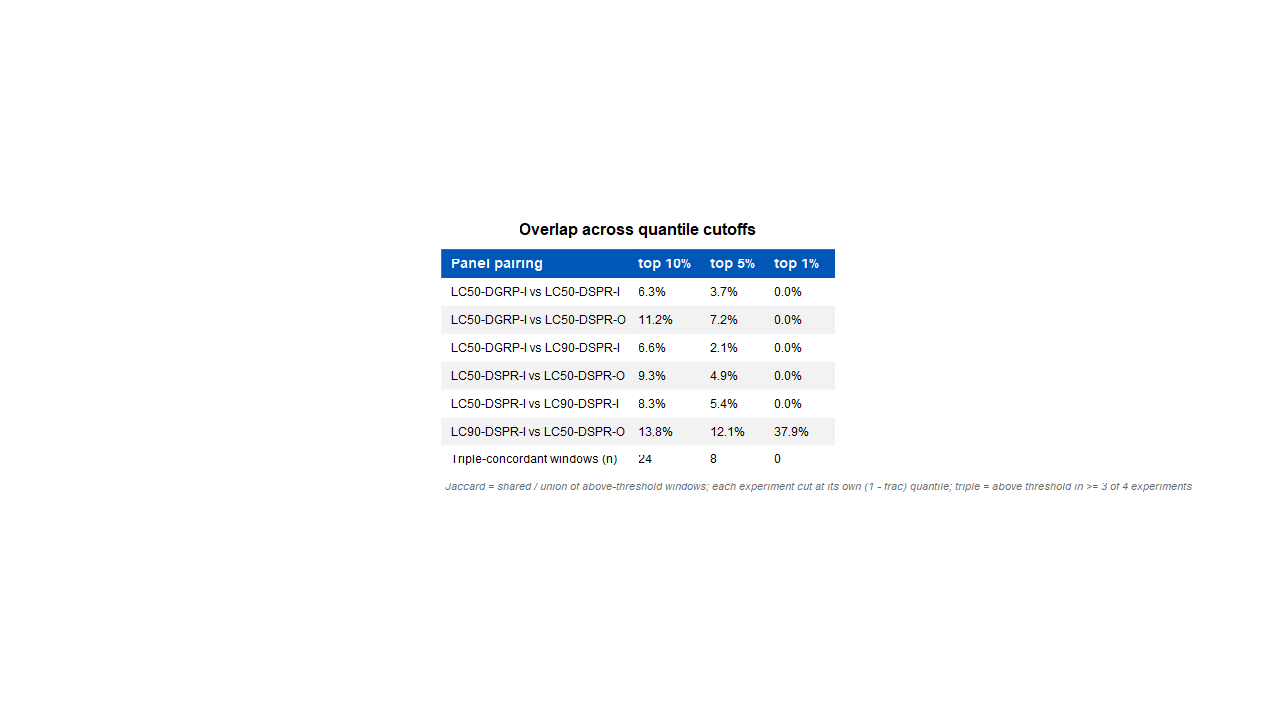

In [10]:
frac_levels <- c(0.10, 0.05, 0.01)
sweep_results <- bind_rows(lapply(frac_levels, function(f) {
  cuts <- sapply(zall, function(l) unname(quantile(B[[l]], 1 - f, na.rm = TRUE)))
  Mf <- sapply(zall, function(l) B[[l]] > cuts[[l]])
  nh <- colSums(Mf); bt <- crossprod(Mf); jc <- bt / (outer(nh, nh, "+") - bt)
  tibble(frac = f, var1 = pairs[, 1], var2 = pairs[, 2], both = bt[pairs], jaccard = jc[pairs])
})) %>% mutate(pair = paste(PANELS[var1], PANELS[var2], sep = " vs "))
write.csv(sweep_results, file.path(DATA, "jaccard_threshold_sweep.csv"), row.names = FALSE)

frac_lab <- c("10%", "5%", "1%")
wide <- sweep_results %>% mutate(frac_lab = factor(sprintf("%.0f%%", 100 * frac), levels = frac_lab)) %>%
  dplyr::select(pair, frac_lab, jaccard) %>%
  pivot_wider(names_from = frac_lab, values_from = jaccard) %>% arrange(pair)
disp <- wide %>% mutate(across(all_of(frac_lab), ~ ifelse(is.na(.x), "-", percent(.x, accuracy = 0.1))))
names(disp) <- c("Panel pairing", paste("top", frac_lab))
tri_counts <- vapply(frac_levels, function(f) {
  cuts <- sapply(zall, function(l) unname(quantile(B[[l]], 1 - f, na.rm = TRUE)))
  sum(rowSums(sapply(zall, function(l) B[[l]] > cuts[[l]])) >= MIN_HITS)
}, integer(1))
disp <- bind_rows(disp, as_tibble(setNames(as.list(c("Triple-concordant windows (n)", as.character(tri_counts))), names(disp))))
print(disp)
save_table_png(disp, "Overlap across quantile cutoffs", file.path(FIGS, "jaccard_threshold_table.png"),
               foot = "Jaccard = shared / union of above-threshold windows; each experiment cut at its own (1 - frac) quantile; triple = above threshold in >= 3 of 4 experiments")

## 9. Genes in triple regions

Gene coordinates come from a pinned Ensembl archive and are cached to `dmel_gene_coords.csv` (all main arms), which notebooks 03 and 04 reuse. Genes are taken from each **triple region** (scan footprint, section 5), not from the 50 kb windows, so the list does not depend on where the sampling grid falls. Window-level genes are kept for reference. Intervals are half-open `[start, end)`.

Data: `dmel_gene_coords.csv`, `triple_region_genes.csv` (File S1), `triple_window_genes.csv`. Figure: `triple_region_genes_table.png`.

gene_coords from cache: 23289 genes
genes in triple regions: 175 distinct (2L_Consensus 108, 2R_1 23, 3L_1 22, 3L_2 22) | in the 50 kb triple windows alone: 89


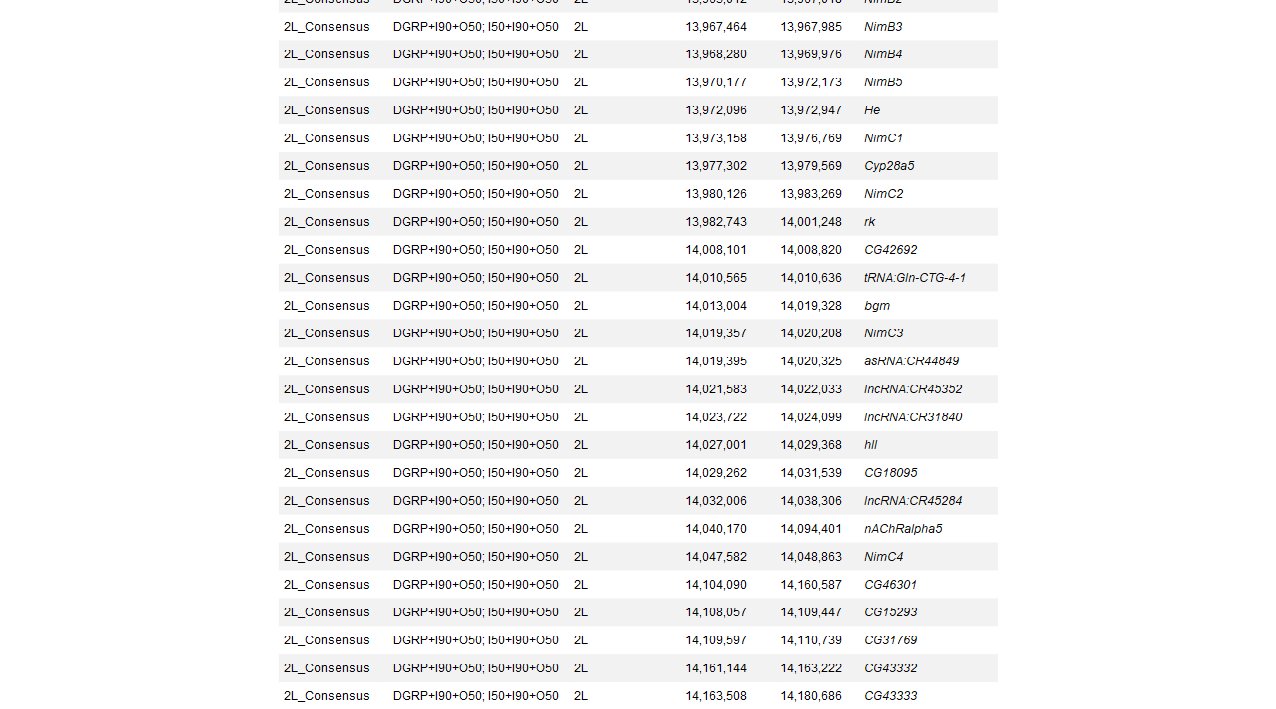

In [11]:
gene_cache <- file.path(DATA, "dmel_gene_coords.csv")
if (file.exists(gene_cache)) {
  gene_coords <- as_tibble(read.csv(gene_cache, stringsAsFactors = FALSE))
  cat("gene_coords from cache:", nrow(gene_coords), "genes\n")
} else {
  arch <- listEnsemblArchives()
  host_url <- arch$url[grepl(ENSEMBL_ARCHIVE, arch$date)]
  stopifnot(length(host_url) == 1)
  ensembl <- useEnsembl(biomart = "genes", dataset = "dmelanogaster_gene_ensembl", host = host_url)
  gene_coords <- getBM(attributes = c("ensembl_gene_id", "external_gene_name", "chromosome_name",
                                      "start_position", "end_position", "strand", "gene_biotype"),
                       filters = "chromosome_name", values = CHROMS, mart = ensembl) %>%
    as_tibble() %>% distinct(ensembl_gene_id, .keep_all = TRUE) %>%
    transmute(ensembl_gene_id, gene_name = external_gene_name, gene_chr = chromosome_name,
              gene_start = start_position, gene_end = end_position,
              gene_strand = ifelse(strand > 0, "+", "-"), biotype = gene_biotype)
  write.csv(gene_coords, gene_cache, row.names = FALSE)
  cat("gene_coords pulled from", host_url, "and cached:", nrow(gene_coords), "genes\n")
}
gene_gr <- GRanges(gene_coords$gene_chr, IRanges(gene_coords$gene_start, gene_coords$gene_end))

## genes overlapping half-open intervals [start, end)
overlap_genes <- function(iv, start_col, end_col, id_cols) {
  h <- findOverlaps(GRanges(iv$chr, IRanges(iv[[start_col]], iv[[end_col]] - 1)), gene_gr)
  bind_cols(iv[queryHits(h), id_cols, drop = FALSE], gene_coords[subjectHits(h), ])
}

triple_region_genes <- overlap_genes(triple_regions, "fp_start", "fp_end",
                                     c("region", "chr", "fp_start", "fp_end", "span_kb", "peaks", "hit_sets", "top_panel")) %>%
  arrange(match(chr, CHROMS), fp_start, gene_start)
triple_window_genes <- overlap_genes(triple_windows, "win_start", "win_end",
                                     c("window_id", "peak", "region", "chr", "win_start", "win_end", "hit_code", "win_max_z")) %>%
  arrange(match(chr, CHROMS), win_start, gene_start)
write.csv(triple_region_genes, file.path(DATA, "triple_region_genes.csv"), row.names = FALSE)
write.csv(triple_window_genes, file.path(DATA, "triple_window_genes.csv"), row.names = FALSE)
cat(sprintf("genes in triple regions: %d distinct (%s) | in the 50 kb triple windows alone: %d\n",
            n_distinct(triple_region_genes$ensembl_gene_id),
            paste(sprintf("%s %d", triple_regions$region,
                          vapply(triple_regions$region, function(r) n_distinct(triple_region_genes$ensembl_gene_id[triple_region_genes$region == r]), 1L)),
                  collapse = ", "),
            n_distinct(triple_window_genes$ensembl_gene_id)))

disp <- triple_region_genes %>%
  mutate(GENE = ifelse(is.na(gene_name) | gene_name == "", ensembl_gene_id, gene_name)) %>%
  distinct(ensembl_gene_id, .keep_all = TRUE) %>%
  transmute(Region = region, Experiments = hit_sets, Chromosome = gene_chr, `START POS` = comma(gene_start), `END POS` = comma(gene_end), GENE)
save_table_png(disp, "Genes in triple regions", file.path(FIGS, "triple_region_genes_table.png"), italic_col = "GENE")

## 10. SNP-level allele frequencies inside triple regions: all four panels

Every site inside any **triple region** (scan footprint, section 5), read from **every** panel's own data: LC50-DSPR-I (Spino3), LC90-DSPR-I (Spino4), LC50-DSPR-O (Spino3Out) from their per-sample VCFs (alt AF = AD[2] / sum AD), LC50-DGRP-I from its per-sample allele-frequency table (`all.csv`, no REF / ALT). Per site and panel: mean AF in T and C, ΔAF = T − C, closed-form quasibinomial `AF ~ T/C` p (identical to `glm`), BH within panel. Sites need folded mean AF ≥ `MIN_MAF` within that panel.

Sample assignment per panel is printed: treated = `treat` regex, control = `ctrl` regex, `drop` excluded, anything else ignored and listed.

Data: `triple_region_AF_<panel>.csv` (per-sample AF, one file per panel, read by 03), `triple_region_snp_af.csv` (per-site summary, all panels; `is_top_panel` marks each region's strongest experiment).

In [12]:
MIN_MAF <- 0.05

## ---- AF source per panel (keyed by z column) --------------------------
AF_SRC <- list(
  z_dspr3     = list(type = "vcf", path = "xQTL/VCF/Spino3_DSPR/calls.chr%s.vcf",
                     treat = "^T", ctrl = "^C", drop = character(0)),          # CHECK drop list
  z_dspr4     = list(type = "vcf", path = VCF_DSPR4,
                     treat = "^T", ctrl = "^C", drop = DSPR_DROP),
  z_outspino3 = list(type = "vcf", path = "xQTL/VCF/Spino3Out_DSPR/calls.chr%s.vcf",
                     treat = "^T", ctrl = "^C", drop = character(0)),          # CHECK drop list
  z_dgrp      = list(type = "csv", path = DGRP_AF,
                     T_cols = c(paste0("A", 6:12, ".af"), "B1.af"),
                     C_cols = paste0("B", 2:9, ".af")))

tri_arms <- intersect(CHROMS, unique(triple_regions$chr))
reg_iv   <- as.data.table(triple_regions)[, .(region, chr, fp_start = as.numeric(fp_start), fp_end = as.numeric(fp_end))]

## attach region to positions (non-equi join on [fp_start, fp_end))
tag_regions <- function(ch, pos) {
  x <- data.table(chr = ch, pos = as.numeric(pos), rid = seq_along(pos))
  reg_iv[x, on = .(chr, fp_start <= pos, fp_end > pos), nomatch = NULL, .(rid, region)]
}

## ---- readers: loc (POS, REF, ALT) + T / C AF matrices, sites inside triple regions only ----
read_vcf_af <- function(src, ch) {
  f <- file.path(IN_DIR, sprintf(src$path, ch))
  if (!file.exists(f)) { message("  missing ", f, ": skipped"); return(NULL) }
  v <- fread(f, skip = "#CHROM", sep = "\t", header = TRUE)
  setnames(v, "#CHROM", "CHROM")
  w <- reg_iv[chr == ch]
  v <- v[inrange(POS, w$fp_start, w$fp_end - 1)]
  if (!nrow(v)) return(NULL)
  samp <- setdiff(names(v)[(match("FORMAT", names(v)) + 1):ncol(v)], src$drop)
  isT <- grepl(src$treat, samp); isC <- grepl(src$ctrl, samp) & !isT
  if (any(!isT & !isC)) message("  ignored (neither treat nor ctrl): ", paste(samp[!isT & !isC], collapse = ", "))
  stopifnot(uniqueN(v$FORMAT) == 1, sum(isT) > 1, sum(isC) > 1)
  fmt  <- strsplit(v$FORMAT[1], ":", fixed = TRUE)[[1]]
  gt_i <- match("GT", fmt); ad_i <- match("AD", fmt)
  af_of <- function(s) {
    f2 <- tstrsplit(s, ":", fixed = TRUE, keep = c(gt_i, ad_i))
    ad <- lapply(tstrsplit(f2[[2]], ",", fixed = TRUE), function(x) suppressWarnings(as.numeric(x)))
    if (length(ad) < 2) return(rep(NA_real_, length(s)))
    tot <- Reduce(`+`, ad[1:2]); a <- ad[[2]] / tot
    a[is.na(f2[[1]]) | f2[[1]] == "./." | !(tot > 0)] <- NA_real_
    a
  }
  A <- matrix(vapply(samp, function(s) af_of(v[[s]]), numeric(nrow(v))), nrow = nrow(v),
              dimnames = list(NULL, samp))
  list(loc = v[, .(POS = as.numeric(POS), REF, ALT)],
       T = A[, isT, drop = FALSE], C = A[, isC, drop = FALSE])
}

dgrp_cache <- NULL
## DGRP per-sample AF from all.csv; no allele columns in this file, so REF / ALT stay NA
## (DGRP is never the strongest experiment for a peak, so it never needs the CADD join)
read_csv_af <- function(src, ch) {
  if (is.null(dgrp_cache)) {
    dgrp_cache <<- fread(file.path(IN_DIR, src$path), select = c("chrom", "pos", src$T_cols, src$C_cols))
    dgrp_cache[, `:=`(chrom = strip_chr(as.character(chrom)), pos = as.numeric(pos))]
  }
  w <- reg_iv[chr == ch]
  d <- dgrp_cache[chrom == ch & inrange(pos, w$fp_start, w$fp_end - 1)]
  if (!nrow(d)) return(NULL)
  list(loc = d[, .(POS = pos, REF = NA_character_, ALT = NA_character_)],
       T = as.matrix(d[, src$T_cols, with = FALSE]), C = as.matrix(d[, src$C_cols, with = FALSE]))
}

## ---- per-sample AF per panel ---------------------------------------------------
af_panel <- function(zc) {
  src <- AF_SRC[[zc]]
  cat(sprintf("%s (%s):\n", PANELS[[zc]], zc))
  out <- rbindlist(lapply(tri_arms, function(ch) {
    r <- if (src$type == "vcf") read_vcf_af(src, ch) else read_csv_af(src, ch)
    if (is.null(r)) return(NULL)
    h <- tag_regions(ch, r$loc$POS)
    cat(sprintf("  %s: %d sites | T = %s | C = %s\n", ch, nrow(h),
                paste(colnames(r$T), collapse = ","), paste(colnames(r$C), collapse = ",")))
    Tm <- as.data.table(r$T[h$rid, , drop = FALSE]); setnames(Tm, paste0("T_", sub("[.]af$", "", colnames(r$T))))
    Cm <- as.data.table(r$C[h$rid, , drop = FALSE]); setnames(Cm, paste0("C_", sub("[.]af$", "", colnames(r$C))))
    cbind(data.table(chr = ch), r$loc[h$rid], h[, .(region)], Tm, Cm)
  }), fill = TRUE)
  if (nrow(out)) fwrite(out, file.path(DATA, sprintf("triple_region_AF_%s.csv", sub("^z_", "", zc))))
  out
}
af_tri <- setNames(lapply(names(AF_SRC), af_panel), names(AF_SRC))

## ---- per-site summary, every panel ----------------------------------------------
qb_two_group <- function(yT, yC) {
  nT <- rowSums(!is.na(yT)); nC <- rowSums(!is.na(yC))
  mT <- rowMeans(yT, na.rm = TRUE); mC <- rowMeans(yC, na.rm = TRUE)
  X2 <- rowSums((yT - mT)^2, na.rm = TRUE) / (mT * (1 - mT)) +
        rowSums((yC - mC)^2, na.rm = TRUE) / (mC * (1 - mC))
  dfr <- nT + nC - 2
  se  <- sqrt(X2 / dfr * (1 / (nT * mT * (1 - mT)) + 1 / (nC * mC * (1 - mC))))
  tt  <- (qlogis(mT) - qlogis(mC)) / se
  p   <- 2 * pt(-abs(tt), dfr); p[!is.finite(tt)] <- 1      # fixed in a group: no evidence
  list(mT = mT, mC = mC, nT = nT, nC = nC, p = p)
}
peak_snps <- rbindlist(lapply(names(af_tri), function(zc) {
  d <- af_tri[[zc]]; if (is.null(d) || !nrow(d)) return(NULL)
  Tm <- as.matrix(d[, grep("^T_", names(d), value = TRUE), with = FALSE])
  Cm <- as.matrix(d[, grep("^C_", names(d), value = TRUE), with = FALSE])
  m  <- rowMeans(cbind(Tm, Cm), na.rm = TRUE)
  ok <- !is.na(m) & pmin(m, 1 - m) >= MIN_MAF
  f  <- qb_two_group(Tm[ok, , drop = FALSE], Cm[ok, , drop = FALSE])
  data.table(d[ok, .(region, chr, POS, REF, ALT)], zcol = zc, panel = PANELS[[zc]],
             T_mean = f$mT, C_mean = f$mC, dAF = f$mT - f$mC, n_T = f$nT, n_C = f$nC, p = f$p)
}))
peak_snps[, FDR := p.adjust(p, method = "BH"), by = panel]
peak_snps[as.data.table(triple_regions)[, .(region, top_panel)], is_top_panel := panel == i.top_panel, on = "region"]
setorder(peak_snps, region, POS, panel)
fwrite(peak_snps, file.path(DATA, "triple_region_snp_af.csv"))

cat(sprintf("sites passing MAF inside triple regions: %d (all panels) | FDR < 0.05: %d\n",
            nrow(peak_snps), sum(peak_snps$FDR < 0.05)))
print(peak_snps[, .(n_snp = .N, n_fdr05 = sum(FDR < 0.05), median_abs_dAF = median(abs(dAF)),
                    top = any(is_top_panel)), by = .(region, panel)])

LC50-DSPR-I (z_dspr3):


  ignored (neither treat nor ctrl): AB8, B1, B2, B3, B4, B5, B6, B7



  2L: 14506 sites | T = T1,T2,T3,T4,T5,T6,T7,T8 | C = C1,C2,C3,C4,C5,C6,C7,C8


  ignored (neither treat nor ctrl): AB8, B1, B2, B3, B4, B5, B6, B7



  2R: 3040 sites | T = T1,T2,T3,T4,T5,T6,T7,T8 | C = C1,C2,C3,C4,C5,C6,C7,C8


...

  2L: 14246 sites | T = T1,T2,T3,T4,T5 | C = C1,C2,C3,C4,C5


  ignored (neither treat nor ctrl): AB8, B1, B2, B3, B4, B5, B6, B7



  2R: 3009 sites | T = T1,T2,T3,T4,T5 | C = C1,C2,C3,C4,C5


  ignored (neither treat nor ctrl): AB8, B1, B2, B3, B4, B5, B6, B7



  3L: 3446 sites | T = T1,T2,T3,T4,T5 | C = C1,C2,C3,C4,C5
LC50-DGRP-I (z_dgrp):
  2L: 28605 sites | T = A6.af,A7.af,A8.af,A9.af,A10.af,A11.af,A12.af,B1.af | C = B2.af,B3.af,B4.af,B5.af,B6.af,B7.af,B8.af,B9.af
  2R: 4602 sites | T = A6.af,A7.af,A8.af,A9.af,A10.af,A11.af,A12.af,B1.af | C = B2.af,B3.af,B4.af,B5.af,B6.af,B7.af,B8.af,B9.af
  3L: 5959 sites | T = A6.af,A7.af,A8.af,A9.af,A10.af,A11.af,A12.af,B1.af | C = B2.af,B3.af,B4.af,B5.af,B6.af,B7.af,B8.af,B9.af
sites passing MAF inside triple regions: 67727 (all panels) | FDR < 0.05: 1152
          region       panel n_snp n_fdr05 median_abs_dAF    top
          <char>      <char> <int>   <int>          <num> <lgcl>
 1: 2L_Consensus LC50-DGRP-I 14758     246    0.009551256  FALSE
 2: 2L_Consensus LC50-DSPR-I 10359       0    0.019214391  FALSE
 3: 2L_Consensus LC50-DSPR-O 10178       2    0.044862139  FALSE
 4: 2L_Consensus LC90-DSPR-I 10694     496    0.042054398   TRUE
 5:         2R_1 LC50-DGRP-I  2889     101    0.010433375  FALSE


## 11. SNP-level CADD dissection (every triple region, strongest experiment)

Run once per arm with a triple region. Each region is dissected with the sites of its **strongest experiment** (`top_panel` from section 5: highest |z| relative to that experiment's own 95th-percentile cutoff, among the experiments that are hits in the region). BH is redone over the sites of each arm × experiment; "hot" = |ΔAF| ≥ `DAF_Q` quantile of that arm × experiment's FDR hits; qualifying = hot and FlyCADD > `CADD_MIN`. LC50-DGRP-I ΔAF at the same position is carried along. DGRP has no REF / ALT, so a region whose strongest experiment is LC50-DGRP-I cannot be matched to FlyCADD (none is, currently).

Data: `cadd_triple_region_snps_<arm>.csv`, `cadd_qualifying_snps_<arm>.csv`, plus `_ALL` versions. Figure: `cadd_triple_regions_<arm>.png/.pdf`.

# A tibble: 4 × 3
  region       cadd_panel  panel      
  <chr>        <chr>       <chr>      
1 2L_Consensus z_dspr4     LC90-DSPR-I
2 2R_1         z_dspr3     LC50-DSPR-I
3 3L_1         z_outspino3 LC50-DSPR-O
4 3L_2         z_dspr3     LC50-DSPR-I
         panel n_sites with_ref_alt
        <char>   <int>        <int>
1: LC50-DGRP-I   21160            0
2: LC50-DSPR-I   15483        15483
3: LC50-DSPR-O   15187        15187
4: LC90-DSPR-I   15897        15897

==== 2L: 2L_Consensus [LC90-DSPR-I] (10694 sites) ====
  LC90-DSPR-I: tested 10694 -> FDR < 0.05: 768 -> with CADD: 763 -> hot (|dAF| >= 90th pct = 0.166): 77 -> CADD > 0.60: 10 SNPs
  qualifying genes on 2L: 5
# A tibble: 6 × 3
  region       gene      n_qualifying_snps
  <chr>        <chr>                 <int>
1 2L_Consensus NA                        4
2 2L_Consensus DIP-kappa                 2
3 2L_Consensus Ance-2                    1
4 2L_Consensus CG43333                   1
5 2L_Consensus CG9008                    1
6

2R: no sites with FDR < 0.05, skipped




==== 3L: 3L_1 [LC50-DSPR-O], 3L_2 [LC50-DSPR-I] (3025 sites) ====


3L: no sites with FDR < 0.05, skipped




ALL arms: 768 FDR hits, 10 qualifying SNPs in 5 genes


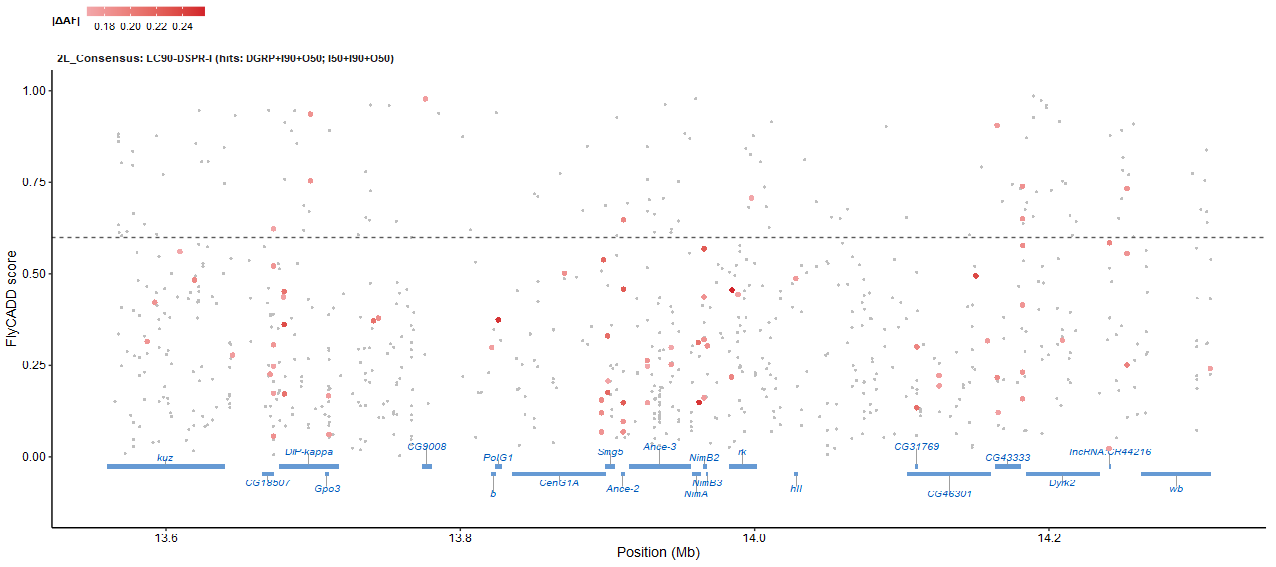

In [13]:
## ---- knobs: loosen here ----------------------------------------------------
FDR_MAX  <- 0.05      # SNP-level BH cutoff
DAF_Q    <- 0.90      # "hot" = |dAF| >= this quantile of the FDR hits
ARMS_RUN <- intersect(CHROMS, unique(triple_regions$chr))   # every arm with a triple region

## dissection experiment per region = the region's strongest experiment (top_panel, section 5)
peak_panel <- triple_regions %>% transmute(region, cadd_panel = names(PANELS)[match(top_panel, PANELS)])
stopifnot(!anyNA(peak_panel$cadd_panel), setequal(peak_panel$region, triple_regions$region))
print(peak_panel %>% mutate(panel = PANELS[cadd_panel]))
print(peak_snps[, .(n_sites = .N, with_ref_alt = sum(!is.na(REF) & !is.na(ALT))), by = panel])   # CADD needs REF/ALT

## FlyCADD per arm (headerless: read with header = FALSE so the first site is not eaten as a header)
read_cadd <- function(arm, need) {
  f <- file.path(IN_DIR, sprintf(FLYCADD, arm))
  if (!file.exists(f)) { message("missing ", f, ": no CADD for arm ", arm); return(NULL) }
  d <- fread(f, header = FALSE, select = unname(FLYCADD_COLS))
  setnames(d, names(FLYCADD_COLS))
  d[, `:=`(CHROM = arm, POS = as.numeric(POS))][POS %in% need]
}
dgrp_delta <- peak_snps[zcol == "z_dgrp", .(CHROM = chr, POS, delta_DGRP = dAF)] %>% as_tibble()

run_cadd <- function(arm) {
  peaks_k <- triple_regions %>% filter(chr == arm) %>% left_join(peak_panel, by = "region")
  snp_tests <- peak_snps[region %in% peaks_k$region] %>% as_tibble() %>%
    inner_join(dplyr::select(peaks_k, region, cadd_panel), by = c("region", "zcol" = "cadd_panel")) %>%
    group_by(zcol) %>% mutate(FDR = p.adjust(p, "BH")) %>% ungroup() %>%      # BH within arm x experiment
    transmute(CHROM = chr, POS, REF, ALT, region, cadd_panel = zcol, p_value = p, FDR,
              delta_AF = dAF, absdelta_AF = abs(dAF))
  cat(sprintf("\n==== %s: %s (%d sites) ====\n", arm,
              paste(sprintf("%s [%s]", peaks_k$region, PANELS[peaks_k$cadd_panel]), collapse = ", "), nrow(snp_tests)))
  hits <- filter(snp_tests, FDR < FDR_MAX)
  if (!nrow(hits)) { message(arm, ": no sites with FDR < ", FDR_MAX, ", skipped"); return(NULL) }

  cadd <- read_cadd(arm, hits$POS)
  if (is.null(cadd) || !nrow(cadd)) cadd <- data.table(POS = numeric(), REF = character(), ALT = character(),
                                                       CADD_Score = numeric(), CHROM = character())
  cadd_snps <- hits %>%
    left_join(as_tibble(cadd), by = c("CHROM", "POS", "REF", "ALT")) %>%
    left_join(dgrp_delta, by = c("CHROM", "POS"))

  ## gene membership
  gh <- findOverlaps(GRanges(cadd_snps$CHROM, IRanges(cadd_snps$POS, cadd_snps$POS)), gene_gr)
  snp_gene <- tibble(.i = queryHits(gh), gene = coalesce(na_if(gene_coords$gene_name[subjectHits(gh)], ""),
                                                       gene_coords$ensembl_gene_id[subjectHits(gh)]),
                     ensembl_gene_id = gene_coords$ensembl_gene_id[subjectHits(gh)])
  cadd_snps <- cadd_snps %>% mutate(.i = row_number()) %>%
    left_join(snp_gene %>% group_by(.i) %>% summarise(genes = paste(unique(gene), collapse = ";"), .groups = "drop"),
              by = ".i") %>% dplyr::select(-.i)

  cadd_snps <- cadd_snps %>% group_by(cadd_panel) %>%
    mutate(daf_cut = unname(quantile(absdelta_AF, DAF_Q, na.rm = TRUE)), hot = absdelta_AF >= daf_cut) %>%
    ungroup() %>% mutate(qualifying = hot & !is.na(CADD_Score) & CADD_Score > CADD_MIN)
  write.csv(cadd_snps, file.path(DATA, sprintf("cadd_triple_region_snps_%s.csv", arm)), row.names = FALSE)

  qual <- cadd_snps %>% mutate(.i = row_number()) %>% filter(qualifying) %>%
    left_join(snp_gene, by = ".i") %>% dplyr::select(-.i, -genes)
  write.csv(qual, file.path(DATA, sprintf("cadd_qualifying_snps_%s.csv", arm)), row.names = FALSE)

  ## ---- funnel: where sites drop out (per dissection panel) ------------------
  fun <- cadd_snps %>% group_by(cadd_panel) %>%
    summarise(fdr = n(), with_cadd = sum(!is.na(CADD_Score)), cut = daf_cut[1],
              hot = sum(hot & !is.na(CADD_Score)), qual = sum(qualifying), .groups = "drop")
  for (i in seq_len(nrow(fun)))
    cat(sprintf(paste0("  %s: tested %d -> FDR < %.2f: %d -> with CADD: %d -> hot (|dAF| >= %.0fth pct = %.3f): %d",
                       " -> CADD > %.2f: %d SNPs\n"),
                PANELS[[fun$cadd_panel[i]]], sum(snp_tests$cadd_panel == fun$cadd_panel[i]), FDR_MAX,
                fun$fdr[i], fun$with_cadd[i], 100 * DAF_Q, fun$cut[i], fun$hot[i], CADD_MIN, fun$qual[i]))
  cat(sprintf("  qualifying genes on %s: %d\n", arm, n_distinct(na.omit(qual$gene))))
  print(qual %>% count(region, gene, name = "n_qualifying_snps") %>% arrange(region, desc(n_qualifying_snps)), n = Inf)

  ## ---- figure: every FDR hit with a CADD score; hot sites emphasized, their genes labeled ----
  pts <- filter(cadd_snps, !is.na(CADD_Score))
  if (!nrow(pts)) { message(arm, ": no FDR hits with a CADD score, figure skipped"); return(list(snps = cadd_snps, qual = qual)) }
  hot <- filter(pts, hot)
  y_lo <- min(c(pts$CADD_Score, CADD_MIN), na.rm = TRUE) - 0.06
  lab_y0 <- y_lo + 0.02                                   # gene bars sit at the bottom of the panel

  hot_gene_idx <- unique(subjectHits(findOverlaps(GRanges(hot$CHROM, IRanges(hot$POS, hot$POS)), gene_gr)))
  gene_lab <- gene_coords[hot_gene_idx, ] %>%
    mutate(label = ifelse(is.na(gene_name) | gene_name == "", ensembl_gene_id, gene_name)) %>%
    inner_join(peaks_k %>% dplyr::select(region, chr, fp_start, fp_end), by = c("gene_chr" = "chr"),
               relationship = "many-to-many") %>%
    filter(gene_end >= fp_start, gene_start < fp_end) %>%
    mutate(xmin = pmax(gene_start, fp_start) / 1e6, xmax = pmin(gene_end, fp_end) / 1e6, xmid = (xmin + xmax) / 2) %>%
    group_by(region) %>% arrange(xmid, .by_group = TRUE) %>%
    mutate(above = row_number() %% 2 == 1,
           bar_ymin = ifelse(above, lab_y0 + 0.005, lab_y0 - 0.015),
           bar_ymax = ifelse(above, lab_y0 + 0.015, lab_y0 - 0.005),
           y_label  = ifelse(above, lab_y0 + 0.035 + 0.015 * ((row_number() - 1) %/% 2 %% 3),
                                    lab_y0 - 0.035 - 0.015 * ((row_number() - 1) %/% 2 %% 3)),
           seg_start = ifelse(above, bar_ymax, bar_ymin)) %>% ungroup()

  peak_lab <- setNames(sprintf("%s: %s (hits: %s)", peaks_k$region, PANELS[peaks_k$cadd_panel], peaks_k$hit_sets),
                       peaks_k$region)
  n_pk <- n_distinct(pts$region)
  g_cadd <- ggplot(pts, aes(POS / 1e6, CADD_Score)) +
    geom_rect(data = gene_lab, aes(xmin = xmin, xmax = xmax, ymin = bar_ymin, ymax = bar_ymax),
              fill = SUP_BLUE, alpha = 0.6, inherit.aes = FALSE) +
    geom_segment(data = gene_lab, aes(x = xmid, xend = xmid, y = seg_start, yend = y_label + ifelse(above, -0.005, 0.005)),
                 colour = "grey60", linewidth = 0.2, inherit.aes = FALSE) +
    geom_text(data = gene_lab, aes(x = xmid, y = y_label, label = label), fontface = "italic",
              size = 1.9, colour = SUP_BLUE, inherit.aes = FALSE) +
    geom_point(data = filter(pts, !hot), colour = "grey75", size = 0.6, stroke = 0) +
    geom_point(data = hot, aes(colour = absdelta_AF), size = 1.3, stroke = 0) +
    geom_hline(yintercept = CADD_MIN, linetype = "dashed", colour = "grey35", linewidth = 0.3) +
    coord_cartesian(ylim = c(y_lo - 0.08, 1)) +
    facet_wrap(~ region, scales = "free_x", labeller = as_labeller(peak_lab), ncol = min(2, n_pk)) +
    scale_colour_gradient(low = "#F2A7AA", high = SUP_RED, name = "|\u0394AF|", labels = scales::label_number(accuracy = 0.01),
                          guide = guide_colourbar(barwidth = unit(25, "mm"), barheight = unit(2, "mm"))) +
    labs(x = "Position (Mb)", y = "FlyCADD score") +
    theme_pub() + theme(legend.position = "top", legend.justification = "left",
                        strip.text = element_text(size = 6.5, face = "bold", hjust = 0))
  save_pub(g_cadd, sprintf("cadd_triple_regions_%s", arm), h = mm(25 + 55 * ceiling(n_pk / 2)))
  print(g_cadd)
  list(snps = cadd_snps, qual = qual)
}

cadd_res <- setNames(lapply(ARMS_RUN, run_cadd), ARMS_RUN)
cadd_res <- cadd_res[!vapply(cadd_res, is.null, logical(1))]
cadd_all <- bind_rows(lapply(cadd_res, `[[`, "snps"))
qual_all <- bind_rows(lapply(cadd_res, `[[`, "qual"))
write.csv(cadd_all, file.path(DATA, "cadd_triple_region_snps_ALL.csv"), row.names = FALSE)
write.csv(qual_all, file.path(DATA, "cadd_qualifying_snps_ALL.csv"),     row.names = FALSE)
cat(sprintf("\nALL arms: %d FDR hits, %d qualifying SNPs in %d genes\n",
            nrow(cadd_all), nrow(qual_all), n_distinct(na.omit(qual_all$gene))))

## 12. Outdoor E&R SNP Manhattans (every track)

Dashed blue = that track's BH q < 0.05; red bands = triple regions (scan footprint of the triple windows). Figure: `ER_SNP_manhattan.png`.

In [14]:
library(ggrastr)

er_hdr <- names(fread(GLM_SNP, nrows = 0))
ER <- fread(GLM_SNP, select = intersect(c("CHROM", "POS", paste0("p_", OUT_TAGS), paste0("q_", OUT_TAGS)), er_hdr))
ER[, CHROM := factor(strip_chr(as.character(CHROM)), levels = CHROMS)]
ER <- ER[!is.na(CHROM)]
setorder(ER, CHROM, POS)
offsets <- ER[, .(chr_len = as.numeric(max(POS))), by = CHROM][, tot := cumsum(chr_len) - chr_len]
ER[offsets, BPcum := POS + i.tot, on = "CHROM"]
er_axis <- ER[, .(center = (max(BPcum) + min(BPcum)) / 2), by = CHROM]

fdr_df <- rbindlist(lapply(OUT_TAGS, function(tg) {
  q <- ER[[paste0("q_", tg)]]; ps <- ER[[paste0("p_", tg)]][!is.na(q) & q <= 0.05]
  data.table(track = tg, fdr_line = if (length(ps)) -log10(max(ps)) else NA_real_)
}))
man <- melt(ER[, c("CHROM", "BPcum", paste0("p_", OUT_TAGS)), with = FALSE], id.vars = c("CHROM", "BPcum"),
            variable.name = "track", value.name = "p", na.rm = TRUE)
man[, logp := -log10(p)]

## drop points that land on an already-drawn pixel (2x output resolution): figure is visually identical
ER_H   <- mm(15 + 25 * length(OUT_TAGS))
X_PIX  <- 2 * W_FULL * 600                                   # 2x pixels across, at 600 dpi
Y_PIX  <- 2 * (ER_H / length(OUT_TAGS)) * 600                # 2x pixels per panel
x_bin  <- diff(range(man$BPcum)) / X_PIX
man[, y_bin := diff(range(logp)) / Y_PIX, by = track]
n0 <- nrow(man)
man <- unique(man[, .(CHROM, track, xb = round(BPcum / x_bin), yb = round(logp / y_bin))])[
  , `:=`(BPcum = xb * x_bin, logp = yb * man[, .(y_bin = y_bin[1]), by = track][.SD, on = "track", y_bin])]
cat(sprintf("points: %d -> %d drawn (rest fall on already-drawn pixels)\n", n0, nrow(man)))

man[, track := factor(sub("^p_", "", track), levels = OUT_TAGS, labels = out_lab(OUT_TAGS))]
fdr_df <- fdr_df[!is.na(fdr_line)][, track := factor(track, levels = OUT_TAGS, labels = out_lab(OUT_TAGS))]
tri_band <- as.data.table(triple_regions)[, CHROM := factor(chr, levels = CHROMS)][
  offsets, on = "CHROM", nomatch = NULL][, .(xmin = fp_start + tot, xmax = fp_end + tot)]

g_er <- ggplot(man, aes(BPcum, logp, colour = CHROM)) +
  geom_rect(data = tri_band, inherit.aes = FALSE, aes(xmin = xmin, xmax = xmax, ymin = -Inf, ymax = Inf),
            fill = SUP_RED, alpha = 0.3) +
  geom_point_rast(size = 0.3, stroke = 0, raster.dpi = 600) +
  geom_hline(data = fdr_df, aes(yintercept = fdr_line), linetype = "dashed", colour = SUP_BLUE, linewidth = 0.3) +
  facet_wrap(~ track, ncol = 1, scales = "free_y") +
  scale_colour_manual(values = rep(c("grey35", "grey70"), length.out = length(CHROMS)), guide = "none") +
  scale_x_continuous(breaks = er_axis$center, labels = er_axis$CHROM, expand = expansion(mult = 0.005)) +
  scale_y_continuous(breaks = scales::breaks_pretty(3)) +
  labs(x = "Chromosome arm", y = expression(-log[10](italic(P)))) +
  theme_pub() + theme(panel.spacing.y = unit(3, "pt"))
save_pub(g_er, "ER_SNP_manhattan", h = ER_H, dpi = 400)
rm(ER, man); invisible(gc())

Warning message:
"package 'ggrastr' was built under R version 4.4.3"


points: 8847425 -> 4497466 drawn (rest fall on already-drawn pixels)


## 13. Outdoor vs xQTL rank concordance (50 kb, median |z|)

For every outdoor track and xQTL panel: Spearman ρ, decomposed into the contribution of each xQTL decile. Null for everything (decile bands, z(D10), `p_circ`) = circular shift of the outdoor ranks within chromosome, which keeps LD-block autocorrelation and only breaks alignment with the xQTL track. `p` (cor.test) assumes independent windows and is anti-conservative; report `p_circ`.

Figures: `Fig_manhattan_decile_<track>.png` per track, `outdoor_xqtl_spearman_heatmap.png`. Data: `outdoor_xqtl_spearman.csv`.

# A tibble: 20 × 7
   track  panel           n     rho p_circ  z_peak  f_peak
   <chr>  <chr>       <int>   <dbl>  <dbl>   <dbl>   <dbl>
 1 pooled LC50-DSPR-I  1951  0.0416 0.924  -1.86   -0.312 
 2 pooled LC50-DGRP-I  1951  0.0509 0.244   1.44    0.549 
 3 pooled LC90-DSPR-I  1951  0.0162 0.827  -1.12   -3.01  
 4 pooled LC50-DSPR-O  1951  0.232  0.0391  1.83    0.457 
 5 tpt1   LC50-DSPR-I  1951 -0.0469 0.691  -1.72    0.676 
 6 tpt1   LC50-DGRP-I  1951  0.0184 0.697   0.816   1.03  
 7 tpt1   LC90-DSPR-I  1951 -0.100  0.279  -2.51    0.594 
 8 tpt1   LC50-DSPR-O  1951  0.197  0.143   1.13    0.410 
 9 tpt2   LC50-DSPR-I  1951 -0.0150 0.843  -1.68    1.18  
10 tpt2   LC50-DGRP-I  1951  0.0871 0.0522  2.47    0.432 
11 tpt2   LC90-DSPR-I  1951  0.0418 0.598   1.00   -0.0726
12 tpt2   LC50-DSPR-O  1951  0.186  0.0140  2.30    0.448 
13 tpt3   LC50-DSPR-I  1951  0.0307 0.935  -2.18   -0.492 
14 tpt3   LC50-DGRP-I  1951  0.0442 0.393   0.956   0.629 
15 tpt3   LC90-DSPR-I  1951  0.0223 0

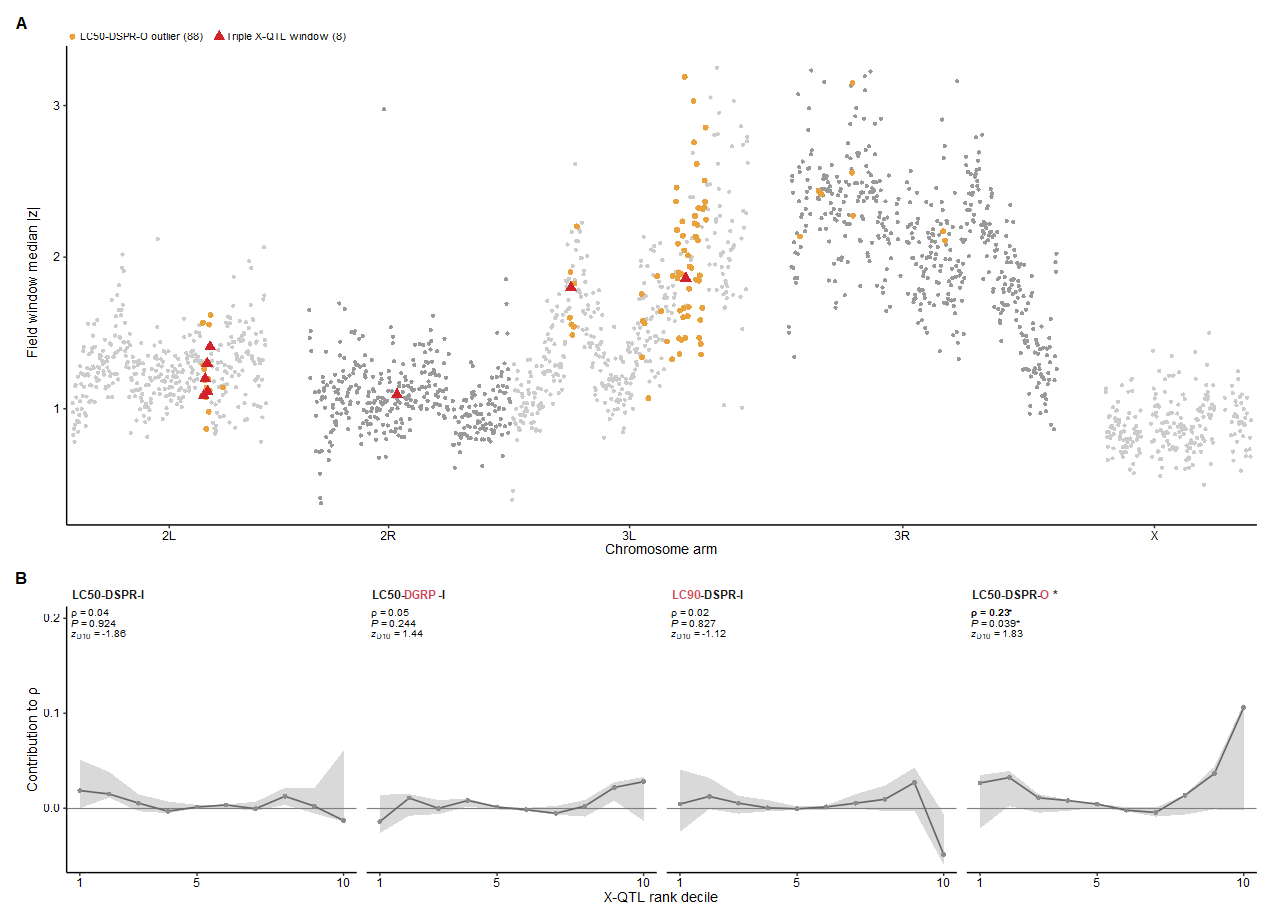

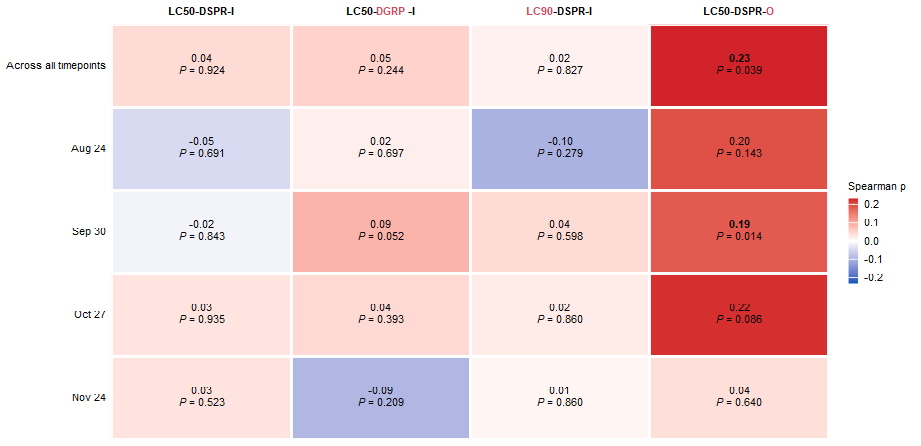

In [15]:
## ---- Figure 4: outdoor Manhattan + rank-decile decomposition ---------------
set.seed(1)                                     # fixed circular-shift nulls -> stable P across reruns
K       <- 10
SUP_RED <- "#D2232A"; SUP_BLUE <- "#0057B8"
FIG_W4  <- 180 / 25.4
FIG_H4  <- 130 / 25.4

df1  <- conc50 %>% filter(chr %in% CHROMS) %>% arrange(match(chr, CHROMS), win_start)
info <- chr_layout(df1, pad = 0)
base <- df1 %>% left_join(dplyr::select(info, chr, offset), by = "chr") %>%
  mutate(cum = win_start + offset, window_id = sprintf("%s:%d", chr, as.integer(win_start)),
         chr_band = match(chr, CHROMS) %% 2 == 0)

rankz <- function(v) { r <- rank(v, ties.method = "average"); (r - mean(r)) / sqrt(mean((r - mean(r))^2)) }
fmt_P <- function(p) ifelse(p < 0.001, "*P* < 0.001", sprintf("*P* = %.3f", p))

decile_one <- function(zcol, ocol, d0 = df1) {
  d  <- d0 %>% dplyr::select(chr, x = all_of(zcol), y = all_of(ocol)) %>% drop_na()
  n  <- nrow(d); rz_x <- rankz(d$x); rz_y <- rankz(d$y)
  idx  <- split(seq_len(n), factor(ntile(rank(d$x, ties.method = "first"), K), levels = 1:K))
  dfun <- function(ry) vapply(idx, function(i) sum(rz_x[i] * ry[i]), numeric(1)) / n
  Sk       <- dfun(rz_y)
  Sk_null  <- t(replicate(NSHIFT, dfun(circ_shift(rz_y, d$chr))))     # NSHIFT x K
  rho_null <- rowSums(Sk_null)                                        # decile contributions sum to rho
  rho <- sum(Sk)
  list(summ = tibble(zcol = zcol, panel = PANELS[[zcol]], n = n, rho = rho,
                     p = suppressWarnings(cor.test(d$x, d$y, method = "spearman")$p.value),
                     p_circ = (1 + sum(abs(rho_null) >= abs(rho))) / (NSHIFT + 1),
                     z_peak = (Sk[K] - mean(Sk_null[, K])) / sd(Sk_null[, K]), f_peak = Sk[K] / rho),
       bins = tibble(zcol = zcol, bin = 1:K, S_k = Sk,
                     null_lo = apply(Sk_null, 2, quantile, 0.025), null_hi = apply(Sk_null, 2, quantile, 0.975)))
}

theme_fig <- theme_classic(base_size = 8) +
  theme(axis.line = element_line(linewidth = 0.3), axis.ticks = element_line(linewidth = 0.3),
        axis.ticks.length = unit(2, "pt"), axis.text = element_text(size = 7, colour = "black"),
        axis.title = element_text(size = 8), plot.margin = margin(4, 6, 4, 4))

make_fig4 <- function(tg) {
  ocol    <- paste0("out_", tg, "_", OUT_STAT)
  CLS     <- c("LC50-DSPR-O outlier", "Triple X-QTL window")
  cls_col <- setNames(c("#E9A23B", SUP_RED), CLS)
  cls_shp <- setNames(c(16, 17), CLS)
  cls_siz <- setNames(c(1.4, 2.5), CLS)

  d <- base %>% mutate(y = .data[[ocol]],
                       cls = case_when(window_id %in% triple_windows$window_id    ~ CLS[2],
                                       z_outspino3 > Z_CUT[["z_outspino3"]]        ~ CLS[1],
                                       TRUE                                         ~ "bg"))
  n_cls   <- table(factor(d$cls, levels = CLS))
  hi      <- filter(d, cls != "bg") %>% mutate(cls = factor(cls, levels = CLS)) %>% arrange(cls)
  leg_lab <- setNames(sprintf("%s (%d)", CLS, as.integer(n_cls)), CLS)

  figA <- ggplot(d, aes(cum, y)) +
    geom_point(data = filter(d, cls == "bg"), aes(colour = chr_band), size = 0.9, stroke = 0) +
    scale_colour_manual(values = c(`TRUE` = "grey60", `FALSE` = "grey80"), guide = "none") +
    new_scale_colour() +
    geom_point(data = hi, aes(colour = cls, shape = cls, size = cls), stroke = 0) +
    scale_colour_manual(values = cls_col, labels = leg_lab, name = NULL, drop = FALSE) +
    scale_shape_manual(values  = cls_shp, labels = leg_lab, name = NULL, drop = FALSE) +
    scale_size_manual(values   = cls_siz, labels = leg_lab, name = NULL, drop = FALSE) +
    scale_x_continuous(breaks = info$center, labels = info$chr, expand = expansion(mult = 0.005)) +
    labs(x = "Chromosome arm", y = sprintf("Field window %s |z|", OUT_STAT)) +
    theme_fig +
    theme(legend.position = "top", legend.justification = "left",
          legend.text = element_text(size = 6, margin = margin(l = 1, r = 6)),
          legend.key.size = unit(7, "pt"), legend.margin = margin(0, 0, 0, 0),
          legend.box.spacing = unit(2, "pt"))

  res  <- lapply(PANEL_ORDER, decile_one, ocol = ocol)
  summ <- bind_rows(lapply(res, `[[`, "summ"))
  sig_p   <- setNames(summ$p_circ < 0.05, summ$zcol)[PANEL_ORDER]
  strip_4 <- setNames(paste0(PANELS_MD[PANEL_ORDER], ifelse(sig_p, " \\*", "")), PANEL_ORDER)
  as_pan  <- function(z) factor(z, levels = PANEL_ORDER, labels = strip_4[PANEL_ORDER])
  bins <- bind_rows(lapply(res, `[[`, "bins")) %>%
    mutate(panel = as_pan(zcol), outside = S_k > null_hi | S_k < null_lo)
  lab_df <- summ %>% mutate(panel = as_pan(zcol), sig = p_circ < 0.05, st = ifelse(sig, "\\*", ""),
                            label = sprintf("%s\u03C1 = %.2f%s%s<br>%s%s<br>*z*<sub>D10</sub> = %.2f",
                                            ifelse(sig, "**", ""), rho, ifelse(sig, "**", ""), st,
                                            fmt_P(p_circ), st, z_peak))

  figB <- ggplot(bins, aes(bin, S_k)) +
    geom_ribbon(aes(ymin = null_lo, ymax = null_hi), fill = "grey85") +
    geom_hline(yintercept = 0, colour = "grey50", linewidth = 0.25) +
    geom_line(colour = "grey40", linewidth = 0.35) +
    geom_point(data = filter(bins, !outside), colour = "grey55", size = 1.1, stroke = 0) +
    geom_point(data = filter(bins,  outside), colour = SUP_BLUE, size = 1.5, stroke = 0) +
    geom_richtext(data = lab_df, aes(x = -Inf, y = Inf, label = label), inherit.aes = FALSE,
                  hjust = 0, vjust = 1, size = 2.1, lineheight = 1.05, fill = NA, label.colour = NA,
                  label.padding = unit(c(2, 0, 0, 3), "pt")) +
    facet_wrap(~ panel, nrow = 1) +
    scale_x_continuous(breaks = c(1, 5, 10)) +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.6))) +
    labs(x = "X-QTL rank decile", y = "Contribution to \u03C1") +
    theme_fig +
    theme(strip.background = element_blank(),
          strip.text = element_markdown(face = "bold", size = 7, hjust = 0),
          panel.spacing.x = unit(6, "pt"))

  fig <- (figA / figB) + plot_layout(heights = c(1.8, 1)) +
    plot_annotation(tag_levels = "A") & theme(plot.tag = element_text(size = 10, face = "bold"))
  list(fig = fig, summ = summ)
}

all_summ <- list()
for (tg in OUT_TAGS) {
  r <- make_fig4(tg)
  fn <- if (tg == PRIMARY) "Fig4_outdoor_concordance" else sprintf("Fig_manhattan_decile_%s", tg)
  ggsave(file.path(FIGS, paste0(fn, ".png")), r$fig, width = FIG_W4, height = FIG_H4, dpi = 600, bg = "white")
  ggsave(file.path(FIGS, paste0(fn, ".pdf")), r$fig, width = FIG_W4, height = FIG_H4, device = cairo_pdf)
  if (tg == PRIMARY) { options(repr.plot.width = FIG_W4 * 1.5, repr.plot.height = FIG_H4 * 1.5); print(r$fig) }
  all_summ[[tg]] <- r$summ %>% mutate(track = tg, track_lab = out_lab(tg), scale = "50kb", stat = OUT_STAT)
}
spearman_main <- bind_rows(all_summ) %>% relocate(track, track_lab, scale, stat)
write.csv(spearman_main, file.path(DATA, "outdoor_xqtl_spearman.csv"), row.names = FALSE)
print(spearman_main %>% dplyr::select(track, panel, n, rho, p_circ, z_peak, f_peak), n = Inf)

## ---- Supplement: rho for every outdoor track x X-QTL panel ------------------
hm <- spearman_main %>%
  mutate(panel = factor(zcol, levels = PANEL_ORDER, labels = PANELS_MD[PANEL_ORDER]),
         track_lab = factor(track_lab, levels = rev(out_lab(OUT_TAGS))),
         lab = sprintf("%s%.2f%s<br>%s", ifelse(p_circ < 0.05, "**", ""), rho,
                       ifelse(p_circ < 0.05, "**", ""), fmt_P(p_circ)))
rlim <- max(abs(hm$rho), na.rm = TRUE)
spearman_heat <- ggplot(hm, aes(panel, track_lab, fill = rho)) +
  geom_tile(colour = "white", linewidth = 0.6) +
  geom_richtext(aes(label = lab), size = 2.2, lineheight = 1.05, fill = NA, label.colour = NA,
                label.padding = unit(0, "pt")) +
  scale_fill_gradient2(low = SUP_BLUE, mid = "white", high = SUP_RED, midpoint = 0,
                       limits = c(-rlim, rlim), name = "Spearman \u03C1",
                       guide = guide_colourbar(barwidth = unit(2, "mm"), barheight = unit(18, "mm"))) +
  scale_x_discrete(expand = c(0, 0), position = "top") + scale_y_discrete(expand = c(0, 0)) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 8) +
  theme(axis.text.x.top = element_markdown(size = 6.5, face = "bold", colour = "black"),
        axis.text.y     = element_text(size = 6.5, colour = "black"),
        panel.grid      = element_blank(),
        legend.title    = element_text(size = 6.5), legend.text = element_text(size = 6),
        plot.margin     = margin(4, 4, 4, 4))
save_pub(spearman_heat, "outdoor_xqtl_spearman_heatmap", w = mm(130), h = mm(18 + 9 * length(OUT_TAGS)))
spearman_heat

### Diagnostic

In [16]:
## ---- Diagnostics: decile baseline, what the null tests, test of top-decile excess ----
set.seed(2)
ocol_d <- paste0("out_", PRIMARY, "_", OUT_STAT)
cat(sprintf("analytic uniform-rank share of top decile: 4*(0.5^3 - 0.4^3) = %.3f\n\n", 4 * (0.5^3 - 0.4^3)))

diag_one <- function(zcol, n_sim = 500) {
  d    <- df1 %>% dplyr::select(chr, x = all_of(zcol), y = all_of(ocol_d)) %>% drop_na()
  n    <- nrow(d); rz_x <- rankz(d$x); rz_y <- rankz(d$y)
  top  <- ntile(rank(d$x, ties.method = "first"), K) == K
  S_top <- function(ry) sum(rz_x[top] * ry[top]) / n
  rho_f <- function(ry) sum(rz_x * ry) / n

  ## (1) uniform-rank share from the real windows
  share_u <- sum(rz_x[top]^2) / sum(rz_x^2)

  ## (2) simulate a field track with the observed rho spread evenly across ranks
  obs_rho <- rho_f(rz_y)
  sim_frac <- replicate(n_sim, {
    ry <- rankz(obs_rho * rz_x + sqrt(1 - obs_rho^2) * rnorm(n))
    S_top(ry) / rho_f(ry)
  })

  ## (3) both nulls: centre ~0, circular shift wider
  circ <- t(replicate(NSHIFT, { ry <- circ_shift(rz_y, d$chr); c(S = S_top(ry), rho = rho_f(ry)) }))
  rand <- t(replicate(NSHIFT, { ry <- sample(rz_y);            c(S = S_top(ry), rho = rho_f(ry)) }))

  ## (4) excess over uniform share vs circular-shift null (one-sided: excess at the top)
  obs_S   <- S_top(rz_y)
  obs_exc <- obs_S - share_u * obs_rho
  exc_c   <- circ[, "S"] - share_u * circ[, "rho"]

  tibble(panel            = PANELS[[zcol]],
         rho              = obs_rho,
         frac_top_obs     = obs_S / obs_rho,
         share_uniform    = share_u,
         frac_top_sim     = mean(sim_frac),
         nullS_mean_circ  = mean(circ[, "S"]),  nullS_sd_circ = sd(circ[, "S"]),
         nullS_mean_rand  = mean(rand[, "S"]),  nullS_sd_rand = sd(rand[, "S"]),
         z_D10_circ       = (obs_S - mean(circ[, "S"])) / sd(circ[, "S"]),
         z_D10_rand       = (obs_S - mean(rand[, "S"])) / sd(rand[, "S"]),
         z_excess         = (obs_exc - mean(exc_c)) / sd(exc_c),
         p_excess_1sided  = (1 + sum(exc_c >= obs_exc)) / (NSHIFT + 1))
}

decile_diag <- bind_rows(lapply(PANEL_ORDER, diag_one))
write.csv(decile_diag, file.path(DATA, "decile_diagnostics.csv"), row.names = FALSE)
print(decile_diag %>% mutate(across(where(is.numeric), ~ signif(.x, 3))), width = Inf)

analytic uniform-rank share of top decile: 4*(0.5^3 - 0.4^3) = 0.244

# A tibble: 4 × 13
  panel          rho frac_top_obs share_uniform frac_top_sim nullS_mean_circ
  <chr>        <dbl>        <dbl>         <dbl>        <dbl>           <dbl>
1 LC50-DSPR-I 0.0416       -0.312         0.244        0.133          0.0231
2 LC50-DGRP-I 0.0509        0.549         0.244        0.281          0.0107
3 LC90-DSPR-I 0.0162       -3.01          0.244        0.485         -0.0335
4 LC50-DSPR-O 0.232         0.457         0.244        0.243          0.0443
  nullS_sd_circ nullS_mean_rand nullS_sd_rand z_D10_circ z_D10_rand z_excess
          <dbl>           <dbl>         <dbl>      <dbl>      <dbl>    <dbl>
1        0.0191     -0.000185          0.0105      -1.89      -1.22   -1.82 
2        0.0119     -0.0000175         0.0107       1.45       2.62    1.81 
3        0.0139      0.00000381        0.0106      -1.1       -4.62   -0.807
4        0.0329     -0.0000853         0.0106       1.87       9

## 14. Robustness: rank-rank Spearman across window size × window stat

Every outdoor track × xQTL panel, rerun at 50 / 100 / 500 kb × mean / median / max outdoor |z|. xQTL at 100 / 500 kb = median of its 50 kb window z's (built in 01). p from the same circular-shift null. The main-text cell (50 kb, median) is outlined.

Data: `outdoor_xqtl_spearman_robustness.csv`. Figure: `outdoor_xqtl_spearman_robustness.png`.

# A tibble: 36 × 6
   scale stat   panel           n    rho p_circ
   <chr> <chr>  <chr>       <int>  <dbl>  <dbl>
 1 50kb  mean   LC50-DGRP-I  1951 0.0515 0.260 
 2 50kb  mean   LC50-DSPR-I  1951 0.0273 0.951 
 3 50kb  mean   LC90-DSPR-I  1951 0.0205 0.805 
 4 50kb  mean   LC50-DSPR-O  1951 0.247  0.0318
 5 50kb  median LC50-DGRP-I  1951 0.0509 0.246 
 6 50kb  median LC50-DSPR-I  1951 0.0416 0.926 
 7 50kb  median LC90-DSPR-I  1951 0.0162 0.816 
 8 50kb  median LC50-DSPR-O  1951 0.232  0.0356
 9 50kb  max    LC50-DGRP-I  1951 0.111  0.0639
10 50kb  max    LC50-DSPR-I  1951 0.0236 0.892 
11 50kb  max    LC90-DSPR-I  1951 0.0818 0.436 
12 50kb  max    LC50-DSPR-O  1951 0.246  0.0151
13 100kb mean   LC50-DGRP-I  1002 0.0528 0.298 
14 100kb mean   LC50-DSPR-I  1002 0.0302 0.956 
15 100kb mean   LC90-DSPR-I  1002 0.0136 0.878 
16 100kb mean   LC50-DSPR-O  1002 0.267  0.0307
17 100kb median LC50-DGRP-I  1002 0.0508 0.276 
18 100kb median LC50-DSPR-I  1002 0.0473 0.937 
19 100kb median LC90-

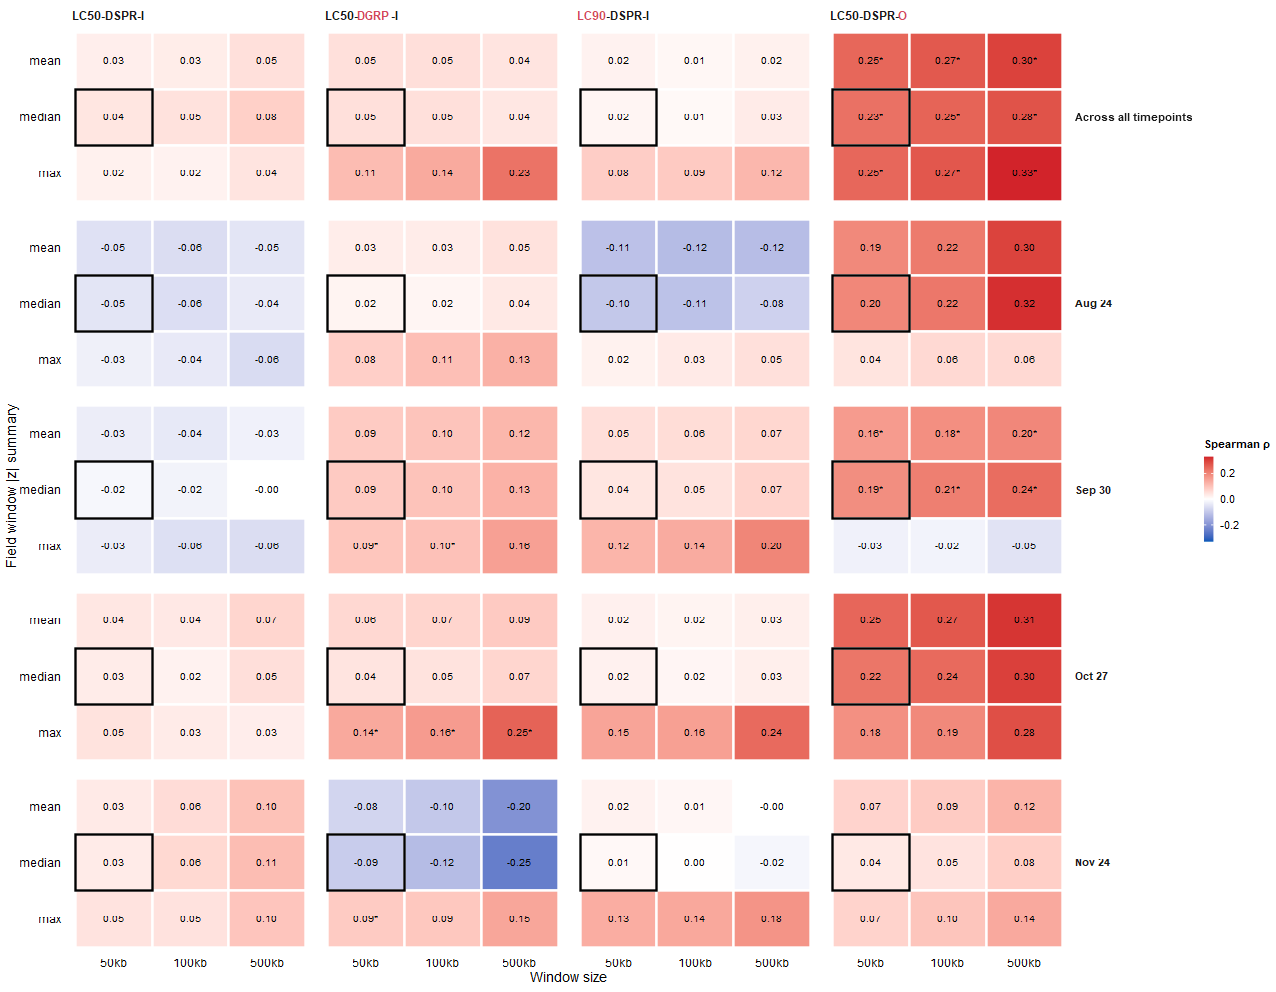

In [17]:
rob <- bind_rows(lapply(names(conc), function(sc) {
  d0 <- conc[[sc]] %>% filter(chr %in% CHROMS) %>% arrange(match(chr, CHROMS), win_start)
  bind_rows(lapply(OUT_TAGS, function(tg) bind_rows(lapply(STATS, function(s) {
    ocol <- paste0("out_", tg, "_", s)
    bind_rows(lapply(names(PANELS), function(zc) {
      d  <- d0 %>% dplyr::select(chr, x = all_of(zc), y = all_of(ocol)) %>% drop_na()
      rx <- rank(d$x); ry <- rank(d$y)
      if (sd(rx) == 0 || sd(ry) == 0) {          # constant track (e.g. every block on the BH q plateau)
        message(sprintf("  %s %s %s vs %s: constant ranks, rho undefined", sc, tg, s, zc))
        return(tibble(scale = sc, track = tg, stat = s, zcol = zc, panel = PANELS[[zc]], n = nrow(d),
                      rho = NA_real_, p_circ = NA_real_))
      }
      rho  <- cor(rx, ry)
      null <- replicate(NSHIFT, cor(rx, circ_shift(ry, d$chr)))
      tibble(scale = sc, track = tg, stat = s, zcol = zc, panel = PANELS[[zc]], n = nrow(d), rho = rho,
             p_circ = (1 + sum(abs(null) >= abs(rho))) / (NSHIFT + 1))
    }))
  }))))
}))
write.csv(rob, file.path(DATA, "outdoor_xqtl_spearman_robustness.csv"), row.names = FALSE)
print(rob %>% filter(track == PRIMARY) %>% dplyr::select(scale, stat, panel, n, rho, p_circ), n = Inf)

rob_hm <- rob %>%
  mutate(scale = factor(scale, levels = names(conc)), stat = factor(stat, levels = rev(STATS)),
         track_lab = factor(out_lab(track), levels = out_lab(OUT_TAGS)),
         panel = factor(zcol, levels = PANEL_ORDER, labels = PANELS_MD[PANEL_ORDER]),
         lab = ifelse(is.na(rho), "n/a", sprintf("%.2f%s", rho, ifelse(p_circ < 0.05, "*", ""))),
         main = scale == "50kb" & stat == OUT_STAT)
rlim <- max(abs(rob_hm$rho), na.rm = TRUE)
g_rob <- ggplot(rob_hm, aes(scale, stat, fill = rho)) +
  geom_tile(colour = "white", linewidth = 0.5) +
  geom_tile(data = filter(rob_hm, main), fill = NA, colour = "black", linewidth = 0.5) +
  geom_text(aes(label = lab), size = 2) +
  facet_grid(track_lab ~ panel) +
  scale_fill_gradient2(low = SUP_BLUE, mid = "white", high = SUP_RED, midpoint = 0,
                       limits = c(-rlim, rlim), name = "Spearman \u03C1",
                       guide = guide_colourbar(barwidth = unit(2, "mm"), barheight = unit(18, "mm"))) +
  labs(x = "Window size", y = "Field window |z| summary") +
  theme_pub() +
  theme(axis.line = element_blank(), axis.ticks = element_blank(),
        strip.text.x = element_markdown(size = 7, face = "bold", hjust = 0),
        strip.text.y = element_text(angle = 0, hjust = 0, size = 6.5, face = "bold"))
save_pub(g_rob, "outdoor_xqtl_spearman_robustness", h = mm(20 + 24 * length(OUT_TAGS)))
g_rob